<a href="https://colab.research.google.com/github/ldelia22/16.32-Redes-Neuronales-en-Bioingenieria-TP3/blob/main/TP3_Regularizacion_DELIA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP3 - Regularización de un MLP para clasificar texto
### Redes Neuronales en Bioingeniería

Se trabaja con el dataset **20 Newsgroups** (20 categorías), con el mismo preprocesamiento, la misma vectorización TF-IDF y la misma división en train y validación de los TP1 y TP2.

## Consigna
En base a las recomendaciones vistas en las clases de regularización, incluir como hiperparámetros posibles en el TP de clasificación de 20 Newsgroups la regularización L1, L2 y L1+L2, el dropout y la BatchNormalization. Para cada caso, tener en cuenta las recomendaciones de clase y observar los valores absolutos de los pesos, los tiempos de entrenamiento, los valores de learning rate y el ruido en las curvas de aprendizaje, justificando con lo visto en clase los fenómenos observados.

## Cómo está organizada la entrega

- La sección 2 describe cada técnica y cómo se implementa.
- La sección 3 presenta el modelo, los regularizadores y el loop de entrenamiento con las mediciones pedidas (pesos, tiempos y ruido).
- La sección 4 contiene la búsqueda de hiperparámetros con Optuna, que incluye L1, L2, L1+L2, dropout, max-norm y BatchNorm.
- La sección 5 reúne los experimentos controlados sobre una red sobredimensionada, con 3 semillas por configuración. El experimento A trata la regularización L2 (en la función de costo y como weight decay desacoplado con AdamW), el B la regularización L1 junto con la esparcidad de los pesos y la poda, el C la combinación L1+L2, el D el dropout, el dropout en la entrada y max-norm, y el E la BatchNormalization y el learning rate.
- La sección 6 compara todas las técnicas en cuanto a pesos, tiempos, learning rate y ruido.
- Las secciones 7 y 8 eligen el modelo con validación (con varias semillas) y lo evalúan en test una única vez.
- La sección 9 contiene las conclusiones y la sección 10 la declaración de uso de herramientas de IA.

### Resultados principales

- El modelo elegido tiene una capa oculta de 256 unidades con dropout en la entrada (0.20) y en la capa oculta (0.35), max-norm 5 y Adam con $\eta = 3.7\cdot10^{-4}$, sin L1, L2 ni BatchNorm. En test obtiene 0.7065 ± 0.0006, un resultado equivalente al del modelo del TP2 (0.7093 ± 0.0012, con una diferencia menor que el error estándar) con la cuarta parte de los parámetros.
- L1 y L2 no mejoraron la validación en ningún caso. Ambas achican los pesos, y L1 además los vuelve esparsos (con $\lambda_1 = 10^{-5}$ se puede podar el 98.5 % de la primera capa sin perder accuracy), pero la accuracy empeora a medida que aumenta $\lambda$.
- El dropout fue la única técnica que mejoró algo la accuracy, que pasó de 0.7419 a 0.7492 con una tasa de 0.7. Max-norm y BatchNorm no aumentaron el máximo, aunque redujeron la subida de la loss de validación al prolongar el entrenamiento.
- Con Adam, ni BatchNorm ni dropout permitieron usar learning rates mayores, a diferencia de lo que se espera con SGD.
- La penalización L1 o L2 en la función de costo aumenta entre un 40 y un 47 % el tiempo por época (un 88 % si se combinan), mientras que AdamW agrega un 8 % y el dropout y BatchNorm entre un 0 y un 2 %.

## 0. Setup

Para que los resultados sean reproducibles se fijan las semillas de Python, NumPy y PyTorch, el orden de los batches se genera con una semilla, se le pide a PyTorch que use algoritmos deterministas (`torch.use_deterministic_algorithms`, que avisa si alguna operación no tiene versión determinista) y se desactiva TF32. En la sección 3.3 se verifica que dos entrenamientos idénticos producen los mismos números. Para que las comparaciones no dependan de una semilla en particular, los experimentos de la sección 5 y la evaluación final se repiten con 3 semillas y se informa la media ± el desvío.

In [ ]:
!pip install -q optuna mlflow

In [ ]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"   # antes de importar torch: cuBLAS determinista en GPU

import re, time, random, copy, warnings, platform, math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

import sklearn
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

import optuna
import mlflow

SEED = 42
SEEDS = [0, 1, 2]


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.use_deterministic_algorithms(True, warn_only=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# MODO_RAPIDO = True achica datos, trials y épocas para verificar en pocos minutos que todo corre.
MODO_RAPIDO = os.environ.get("TP3_MODO_RAPIDO", "0") == "1"

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("tp3_regularizacion")
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)

gpu = torch.cuda.get_device_name(0) if device.type == "cuda" else "-"
print(f"Python {platform.python_version()} | torch {torch.__version__} | scikit-learn {sklearn.__version__} | "
      f"optuna {optuna.__version__} | mlflow {mlflow.__version__}")
print(f"Dispositivo: {device} | GPU: {gpu} | MODO_RAPIDO = {MODO_RAPIDO}")

2026/11/13 23:34:47 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/13 23:34:47 INFO mlflow.store.db.utils: Updating database tables
2026/11/13 23:34:50 INFO mlflow.tracking.fluent: Experiment with name 'tp3_regularizacion' does not exist. Creating a new experiment.


Python 3.13.16 | torch 2.14.1+cu130 | scikit-learn 1.6.1 | optuna 5.0.0 | mlflow 3.18.0
Dispositivo: cuda | GPU: Tesla T4 | MODO_RAPIDO = False


In [ ]:
for pkg in ["stopwords", "wordnet", "omw-1.4", "punkt", "punkt_tab"]:
    nltk.download(pkg, quiet=True)

## 1. Datos

El preprocesamiento queda fijo en el elegido por validación en el TP2 (sacar stopwords, lematizar, unigramas, `max_features=40000`, `min_df=1`), porque este TP estudia la regularización del modelo, no la representación del texto. El split train/validación es el mismo de los TP anteriores (estratificado 80/20, `random_state=42`), así que los números de validación son comparables. El test oficial se usa una sola vez, en la sección 8.

Los datos entran a la GPU como tensores densos y los batches se arman indexando con una permutación, como en el TP2.

In [ ]:
PREPRO = {"remove_stopwords": True, "normalization": "lemmatize", "ngram_range": (1, 1), "max_features": 40000, "min_df": 1}
STOP_WORDS = set(stopwords.words("english"))
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text):
    tokens = [t for t in word_tokenize(text.lower()) if t.isalpha()]
    tokens = [t for t in tokens if t not in STOP_WORDS]
    return " ".join(LEMMATIZER.lemmatize(t) for t in tokens)


newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test = fetch_20newsgroups(subset="test", remove=("headers", "footers", "quotes"))
class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
train_data, y_train_all = list(newsgroups_train.data), np.asarray(newsgroups_train.target)
test_data, y_test_all = list(newsgroups_test.data), np.asarray(newsgroups_test.target)
if MODO_RAPIDO:
    train_data, y_train_all = train_data[:2500], y_train_all[:2500]
    test_data, y_test_all = test_data[:1000], y_test_all[:1000]

t0 = time.perf_counter()
train_proc = [preprocess_text(t) for t in train_data]
test_proc = [preprocess_text(t) for t in test_data]
print(f"Preprocesamiento: {time.perf_counter() - t0:.0f} s | train {len(train_proc)} | test {len(test_proc)}")

idx_tr, idx_val = train_test_split(np.arange(len(train_proc)), test_size=0.2, random_state=SEED, stratify=y_train_all)
vec = TfidfVectorizer(ngram_range=PREPRO["ngram_range"], max_features=PREPRO["max_features"], min_df=PREPRO["min_df"])
Xs_tr = vec.fit_transform([train_proc[i] for i in idx_tr])        # vocabulario e IDF aprendidos solo con train
Xs_val = vec.transform([train_proc[i] for i in idx_val])


def to_device_dense(X):
    """Matriz dispersa de scipy -> tensor denso float32 en `device`, sin armar la matriz densa en la CPU."""
    X = X.tocsr().astype(np.float32)
    t = torch.sparse_csr_tensor(torch.from_numpy(X.indptr).long(), torch.from_numpy(X.indices).long(),
                                torch.from_numpy(X.data), size=X.shape)
    return t.to(device).to_dense()


X_tr, X_val = to_device_dense(Xs_tr), to_device_dense(Xs_val)
y_tr = torch.tensor(y_train_all[idx_tr], dtype=torch.long, device=device)
y_val = torch.tensor(y_train_all[idx_val], dtype=torch.long, device=device)
D_IN = X_tr.shape[1]
print(f"Train de búsqueda: {len(idx_tr)} docs | Validación: {len(idx_val)} docs | Vocabulario: {D_IN} términos")

Preprocesamiento: 31 s | train 11314 | test 7532
Train de búsqueda: 9051 docs | Validación: 2263 docs | Vocabulario: 40000 términos


## 2. Técnicas de regularización

#### Sobreajuste
El overfitting es un problema de **alta varianza**, en el que un modelo con demasiados parámetros respecto de la cantidad de observaciones encuentra soluciones demasiado específicas para el conjunto de entrenamiento. El TP2 lo mostró en este mismo problema, donde una red de 3 capas de 2048 unidades alcanzaba el techo de accuracy en train mientras su loss de validación se multiplicaba por 2.3. Cuando no es posible conseguir más datos, las alternativas son ajustar la cantidad de parámetros, cortar el entrenamiento con early stopping o regularizar. Además, **los pesos crecen cuando hay overfitting**, ya que el modelo se vuelve muy seguro de sus predicciones (asigna probabilidades cercanas a 0 o 1) aunque la frontera de decisión no cambie. Por ese motivo, en este TP se sigue la evolución de la magnitud de los pesos.

#### Regularización L2 (Ridge)
Se agrega a la función de costo un término proporcional al cuadrado de los pesos,

$$J_R(w) = J(w) + \lambda_2 \sum_i w_i^2 .$$

Su gradiente, $2\lambda_2 w_i$, es proporcional al peso, de modo que los pesos grandes se reducen más que los chicos y el histograma se concentra alrededor de cero sin llegar a valores exactamente nulos. La penalización se aplica capa por capa a los pesos ($W$) y no a los sesgos, que habitualmente no se regularizan. En este TP, $\lambda_2$ se aplica a los pesos de todas las capas `Linear` y a ningún sesgo ni parámetro de BatchNorm.

#### L2 con Adam, acoplada o desacoplada
Al sumar $\lambda_2\sum w^2$ al costo, el término $2\lambda_2 w$ pasa por el optimizador. Con SGD esto equivale a encoger los pesos en una proporción fija en cada paso (lo que se conoce como weight decay), pero con Adam el término se divide por $\sqrt{\hat v}$, como el resto del gradiente, y su efecto pasa a depender de la escala del gradiente de cada peso. **AdamW** (Loshchilov y Hutter) desacopla la penalización y aplica $w \leftarrow w - \eta\,\lambda_{wd}\,w$ directamente, por fuera del cociente de Adam. En el experimento A se comparan ambas formas.

#### Regularización L1 (LASSO)

$$J_R(w) = J(w) + \lambda_1 \sum_i |w_i| .$$

Su gradiente es $\lambda_1\,\text{sign}(w_i)$ y tiene el mismo valor para pesos grandes y chicos, por lo que empuja a todos hacia cero con la misma fuerza y los menos útiles terminan en valores cercanos a cero. De esta forma produce **pesos esparsos** y realiza una selección de parámetros. Después de entrenar con L1 es posible anular los pesos chicos sin modificar el resultado, lo que se verifica en el experimento B con una prueba de poda.

#### L1+L2 (elastic net)
Combina ambas penalizaciones, sumando la esparcidad que produce L1 al encogimiento suave de L2.

#### Dropout
Durante el entrenamiento se anula al azar una fracción $p$ de las activaciones de una capa (el *dropout rate*, igual a $1-$`keep_prob`) y las restantes se dividen por `keep_prob` para conservar el valor esperado. En evaluación no se anula ninguna. Las recomendaciones habituales son usar valores entre 20 % y 50 %, aplicarlo sobre una red grande y también sobre la capa de entrada, subir el learning rate (entre 10 y 100 veces con SGD, con momentum de 0.9 a 0.99) y combinarlo con **max-norm**. Como el modelo cambia en cada paso, se espera que la accuracy de train medida durante el entrenamiento sea más ruidosa que la de validación.

#### Max-norm
A diferencia de las anteriores, es una restricción y no un término del costo. Después de cada paso, si el vector de pesos que entra a una unidad oculta tiene norma mayor que $c$, se lo reescala para que su norma sea $c$. Se recomiendan valores del orden de 4 o 5, aplicados a los pesos y no a los sesgos.

#### BatchNormalization
Normaliza la salida de cada unidad con la media y la varianza del mini-batch y luego aplica una escala $\gamma$ y un desplazamiento $\beta$ que se aprenden. La capa densa se define sin sesgo (el $\beta$ de BatchNorm cumple esa función) y la activación se ubica después de la BatchNorm. En evaluación se usan promedios móviles de la media y la varianza. El `momentum=0.99` por defecto de Keras equivale al `momentum=0.1` de PyTorch, que indica el peso del batch nuevo. En sentido estricto es una técnica para **acelerar** el entrenamiento, porque permite usar learning rates más altos, y su efecto regularizador es un subproducto del ruido que introduce estimar la media y la varianza en cada batch. Además, no se suele combinar con dropout.

#### Mediciones en cada entrenamiento
Para responder a lo que pide la consigna, en cada entrenamiento se registra el valor absoluto medio de los pesos de cada capa época por época, el histograma final de los pesos de la primera capa y la fracción de pesos casi nulos (|w| < $10^{-3}$). También se mide el tiempo de cada época de entrenamiento, sincronizando la GPU. El learning rate se barre en el experimento E y en la búsqueda, junto con la regularización. El ruido se cuantifica de tres maneras, mediante la dispersión de la loss de cada batch alrededor de su promedio móvil (el ruido paso a paso de la curva de train), la diferencia entre la accuracy de train medida durante la época (con el dropout activo y las estadísticas de batch) y la medida al final en modo evaluación, y las oscilaciones de la accuracy de validación de una época a la siguiente.

## 3. Modelo y entrenamiento

### 3.1 MLP con regularizadores configurables

Cada capa oculta es `Linear → [BatchNorm] → activación → [Dropout]`. Con BatchNorm, la `Linear` va sin sesgo. Opcionalmente hay dropout sobre la entrada (los términos TF-IDF). La capa de salida es una `Linear` que da los logits (la softmax está dentro de `CrossEntropyLoss`, como en el TP1).

In [ ]:
ACTIVATIONS = {"relu": nn.ReLU, "gelu": nn.GELU, "elu": nn.ELU, "tanh": nn.Tanh}


class RegMLP(nn.Module):
    def __init__(self, input_dim, hidden, num_classes, activation="relu", dropout_in=0.0, dropout_h=0.0, batchnorm=False):
        super().__init__()
        layers, d = [], input_dim
        if dropout_in > 0:
            layers.append(nn.Dropout(dropout_in))
        for h in hidden:
            layers.append(nn.Linear(d, h, bias=not batchnorm))
            if batchnorm:
                layers.append(nn.BatchNorm1d(h))       # momentum=0.1 en PyTorch = 0.99 en Keras
            layers.append(ACTIVATIONS[activation]())
            if dropout_h > 0:
                layers.append(nn.Dropout(dropout_h))
            d = h
        layers.append(nn.Linear(d, num_classes))
        self.net = nn.Sequential(*layers)
        self.linears = [m for m in self.net if isinstance(m, nn.Linear)]

    def forward(self, x):
        return self.net(x)


def kernel_weights(model):
    """Pesos W de las capas Linear (sin sesgos ni parámetros de BatchNorm): lo que se regulariza."""
    return [m.weight for m in model.linears]


def penalty(model, l1, l2):
    """Término de regularización que se suma a la entropía cruzada: l1·Σ|w| + l2·Σw² sobre los pesos de todas las capas."""
    W = kernel_weights(model)
    p = torch.zeros((), device=W[0].device)
    if l1 > 0:
        p = p + l1 * sum(w.abs().sum() for w in W)
    if l2 > 0:
        p = p + l2 * sum((w * w).sum() for w in W)
    return p


@torch.no_grad()
def apply_max_norm(model, c):
    """Max-norm: el vector de pesos que entra a cada unidad oculta (fila de W) se reescala si su norma supera c."""
    for m in model.linears[:-1]:
        m.weight.copy_(torch.renorm(m.weight, p=2, dim=0, maxnorm=c))


def make_optimizer(model, cfg):
    """Adam con la L2 dentro del costo (acoplada), o AdamW con weight decay desacoplado aplicado solo a los pesos W."""
    betas = (cfg.get("beta1", 0.9), cfg.get("beta2", 0.999))
    wd = cfg.get("adamw_wd", 0.0)
    if wd > 0:
        W = kernel_weights(model)
        ids = {id(p) for p in W}
        rest = [p for p in model.parameters() if id(p) not in ids]
        return torch.optim.AdamW([{"params": W, "weight_decay": wd}, {"params": rest, "weight_decay": 0.0}],
                                 lr=cfg["lr"], betas=betas)
    return torch.optim.Adam(model.parameters(), lr=cfg["lr"], betas=betas)


def count_params(model):
    return sum(p.numel() for p in model.parameters())


_m = RegMLP(D_IN, [512, 512], NUM_CLASSES, dropout_in=0.2, dropout_h=0.5, batchnorm=True)
print(_m)
print(f"Parámetros: {count_params(_m):,} | pesos W regularizables: {sum(w.numel() for w in kernel_weights(_m)):,}")
_x = torch.rand(8, D_IN)
print("Penalización inicial  L1·Σ|w| con λ1=1e-6:", round(penalty(_m, 1e-6, 0).item(), 4),
      "| L2·Σw² con λ2=1e-4:", round(penalty(_m, 0, 1e-4).item(), 4))

RegMLP(
  (net): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=40000, out_features=512, bias=False)
    (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.5, inplace=False)
    (5): Linear(in_features=512, out_features=512, bias=False)
    (6): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): Dropout(p=0.5, inplace=False)
    (9): Linear(in_features=512, out_features=20, bias=True)
  )
)
Parámetros: 20,754,452 | pesos W regularizables: 20,752,384
Penalización inicial  L1·Σ|w| con λ1=1e-6: 0.0572 | L2·Σw² con λ2=1e-4: 0.0348


La penalización se calcula sobre **todos** los pesos $W$, pero lo que importa para el entrenamiento es el gradiente que recibe cada peso, $\lambda_1\,\text{sign}(w)$ o $2\lambda_2 w$, que no depende del tamaño de la red. Aun así, los $\lambda$ útiles resultan mucho menores que los habituales en redes chicas (por ejemplo, $\lambda = 10^{-4}$ en una red de 2.000 parámetros), porque lo que cuenta es el tamaño de ese gradiente frente al que aportan los datos. Con entradas TF-IDF dispersas, la mayoría de los pesos de la primera capa corresponde a palabras que aparecen en pocos documentos y recibe un gradiente de los datos muy chico. Además, con la L2 dentro de la función de costo, Adam amplifica la penalización justamente en esos pesos, como se ve en el análisis A.

### 3.2 Loop de entrenamiento y mediciones

`train_model` entrena con Adam (o AdamW) y, al final de cada época, mide la loss y la accuracy de train en modo evaluación (sin dropout y con los promedios móviles de BatchNorm) y de validación, además de la loss y la accuracy de train en modo entrenamiento acumuladas durante la época. También guarda la loss de cada batch para estimar el ruido paso a paso, el valor absoluto medio de los pesos de cada capa, la fracción de pesos casi nulos de la primera capa y el tiempo de la época.

La loss que se informa es siempre la entropía cruzada, sin el término de regularización, para que pueda compararse entre configuraciones. Al terminar el entrenamiento se guarda el histograma de los pesos de la primera capa y se realiza una prueba de poda, que consiste en anular los pesos de la primera capa con |w| menor que un umbral y volver a medir la accuracy de validación. Si se indica `patience`, el entrenamiento se corta cuando la accuracy de validación no mejora durante esa cantidad de épocas (early stopping).

In [ ]:
def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def evaluate(model, X, y, chunk=4096):
    model.eval()
    tot, correct = 0.0, 0
    for i in range(0, len(X), chunk):
        logits = model(X[i:i + chunk])
        tot += F.cross_entropy(logits, y[i:i + chunk], reduction="sum").item()
        correct += (logits.argmax(1) == y[i:i + chunk]).sum().item()
    return tot / len(X), correct / len(X)


PRUNE_THRESHOLDS = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2]
HIST_BINS = np.linspace(-8, 0, 65)       # bins de log10|w|


@torch.no_grad()
def posthoc(model, X_val_, y_val_):
    """Histograma de log10|w| de la primera capa y prueba de poda (se ponen en cero los |w| < umbral)."""
    W = model.linears[0].weight
    a = W.abs().flatten()
    hist = np.histogram(torch.log10(a.clamp_min(1e-12)).cpu().numpy(), bins=HIST_BINS)[0]
    lin_hist = np.histogram(W.flatten().cpu().numpy(), bins=np.linspace(-0.15, 0.15, 121))[0]
    W0 = W.clone()
    prune = []
    for thr in PRUNE_THRESHOLDS:
        mask = W0.abs() >= thr
        W.copy_(W0 * mask)
        prune.append((thr, 1 - mask.float().mean().item(), evaluate(model, X_val_, y_val_)[1]))
    W.copy_(W0)
    return {"hist_log": hist, "hist_lin": lin_hist, "prune": prune}


def train_model(cfg, X_tr_, y_tr_, X_val_, y_val_, *, epochs, seed, patience=None, trial=None, eval_train=True):
    set_seed(seed)
    model = RegMLP(X_tr_.shape[1], cfg["hidden"], NUM_CLASSES, cfg.get("activation", "relu"), cfg.get("dropout_in", 0.0),
                   cfg.get("dropout_h", 0.0), cfg.get("batchnorm", False)).to(device)
    opt = make_optimizer(model, cfg)
    l1, l2, mn = cfg.get("l1", 0.0), cfg.get("l2", 0.0), cfg.get("max_norm", 0)
    gen = torch.Generator().manual_seed(seed)
    n, bs = len(X_tr_), cfg["batch_size"]
    keys = ["train_loss", "train_acc", "val_loss", "val_acc", "run_loss", "run_acc", "epoch_time", "wabs", "frac_small"]
    h = {k: [] for k in keys}
    h["step_loss"] = []
    best_acc, best_ep, status, best_state = -1.0, 0, "completed", None

    for ep in range(1, epochs + 1):
        model.train()
        sync()
        t0 = time.perf_counter()
        perm = torch.randperm(n, generator=gen).to(device)
        step_losses, run_correct = [], torch.zeros((), device=device, dtype=torch.long)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            if len(idx) < 2:          # BatchNorm necesita al menos 2 ejemplos
                continue
            xb, yb = X_tr_[idx], y_tr_[idx]
            opt.zero_grad(set_to_none=True)
            logits = model(xb)
            ce = F.cross_entropy(logits, yb)
            loss = ce + penalty(model, l1, l2) if (l1 > 0 or l2 > 0) else ce
            loss.backward()
            opt.step()
            if mn:
                apply_max_norm(model, mn)
            step_losses.append(ce.detach())
            run_correct += (logits.argmax(1) == yb).sum()
        sync()
        h["epoch_time"].append(time.perf_counter() - t0)

        sl = torch.stack(step_losses).cpu().numpy()
        h["step_loss"].append(sl)
        h["run_loss"].append(float(sl.mean()))
        h["run_acc"].append(run_correct.item() / n)
        if eval_train:
            trl, tra = evaluate(model, X_tr_, y_tr_)
        else:
            trl, tra = np.nan, np.nan
        if X_val_ is not None:
            vl, va = evaluate(model, X_val_, y_val_)
        else:              # entrenamiento final: no se mide nada sobre otro conjunto durante el entrenamiento
            vl, va = np.nan, np.nan
        h["train_loss"].append(trl); h["train_acc"].append(tra); h["val_loss"].append(vl); h["val_acc"].append(va)
        with torch.no_grad():
            h["wabs"].append([m.weight.abs().mean().item() for m in model.linears])
            h["frac_small"].append((model.linears[0].weight.abs() < 1e-3).float().mean().item())

        if not np.isfinite(h["run_loss"][-1]):
            status = "diverged"
            break
        if va > best_acc:
            best_acc, best_ep = va, ep
        if trial is not None:
            trial.report(best_acc, ep)
        if patience is not None and ep - best_ep >= patience:
            status = "early_stop"
            break

    with torch.no_grad():
        rn = model.linears[0].weight.norm(dim=1)       # norma del vector de pesos que entra a cada unidad de la 1ª capa oculta
    h.update(best_val_acc=max(best_acc, 0.0), best_epoch=best_ep, status=status, epochs_run=len(h["val_acc"]),
             n_params=count_params(model), train_time=float(np.sum(h["epoch_time"])),
             row_norm_max=rn.max().item(), row_norm_mean=rn.mean().item())
    return model, h


def step_noise(h, last=5, window=15):
    """Ruido paso a paso: desvío de la loss de cada batch alrededor de su promedio móvil, relativo a la loss media
    (últimas `last` épocas)."""
    s = np.concatenate(h["step_loss"][-last:])
    if len(s) <= window:
        return np.nan
    ma = np.convolve(s, np.ones(window) / window, mode="valid")
    resid = s[window // 2: window // 2 + len(ma)] - ma
    return float(resid.std() / max(s.mean(), 1e-8))


def val_jitter(h, start=10):
    """Oscilación de la curva de validación: desvío de las diferencias época a época de la val acc (desde `start`)."""
    v = np.array(h["val_acc"][start:])
    return float(np.diff(v).std()) if len(v) > 2 else np.nan

### 3.3 Verificación de reproducibilidad

Se entrena dos veces el mismo modelo, con dropout y BatchNorm para que intervengan los generadores aleatorios y las estadísticas de batch, y se comparan las métricas época por época.

In [ ]:
_cfg = {"hidden": [256], "dropout_h": 0.3, "batchnorm": True, "l2": 1e-5, "lr": 1e-3, "batch_size": 128}
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    _, _h1 = train_model(_cfg, X_tr, y_tr, X_val, y_val, epochs=3, seed=0)
    _, _h2 = train_model(_cfg, X_tr, y_tr, X_val, y_val, epochs=3, seed=0)
for k in ["train_loss", "val_loss", "val_acc"]:
    print(f"{k:10s} corrida 1: {np.round(_h1[k], 6)} | corrida 2: {np.round(_h2[k], 6)} | idénticas: {_h1[k] == _h2[k]}")
avisos = sorted({str(w.message)[:150] for w in caught if "determinis" in str(w.message).lower()})
print("Avisos de operaciones sin versión determinista:", avisos if avisos else "ninguno")

train_loss corrida 1: [0.832688 0.12054  0.09492 ] | corrida 2: [0.832688 0.12054  0.09492 ] | idénticas: True
val_loss   corrida 1: [1.424345 0.930092 0.936794] | corrida 2: [1.424345 0.930092 0.936794] | idénticas: True
val_acc    corrida 1: [0.749448 0.744145 0.738842] | corrida 2: [0.749448 0.744145 0.738842] | idénticas: True
Avisos de operaciones sin versión determinista: ninguno


## 4. Búsqueda de hiperparámetros con Optuna

La regularización se incluye como hiperparámetro de la búsqueda, junto con la arquitectura y el entrenamiento, según la tabla siguiente.

| Grupo | Hiperparámetro | Valores |
|---|---|---|
| Arquitectura | `n_layers` | 1, 2, 3 |
| | `n_units_l0` … `n_units_l2` | 256, 512, 1024 |
| | `activation` | relu, gelu |
| Entrenamiento | `lr` | $10^{-4}$ a $3\cdot10^{-2}$ (log) |
| | `batch_size` | 64, 128, 256 |
| Regularización de pesos | `reg_type` | none, l1, l2, l1_l2 |
| | `l1` (si corresponde) | $10^{-9}$ a $10^{-5}$ (log) |
| | `l2` (si corresponde) | $10^{-8}$ a $10^{-4}$ (log) |
| Dropout | `dropout_in` | 0 a 0.5 |
| | `dropout_h` | 0 a 0.7 |
| | `max_norm` | ninguno, 3, 4, 5 |
| BatchNorm | `batchnorm` | False, True |

Los rangos de $\lambda_1$ y $\lambda_2$ se eligieron con una calibración previa sobre esta misma red. Por debajo del mínimo la penalización no modifica los pesos de forma apreciable, y por encima del máximo la red ya no logra ajustar el train. El optimizador es Adam, que fue el de mejor desempeño en el TP2.

Cada trial entrena hasta `MAX_EPOCHS_SEARCH` épocas con early stopping (paciencia 5) y devuelve la mejor accuracy de validación. No se usa pruning porque en el TP2 la misma búsqueda sin pruning llegó a un resultado igual o mejor, dado que el pruner descartaba configuraciones de aprendizaje lento, y la regularización tiende precisamente a hacer más lento el aprendizaje.

In [ ]:
N_TRIALS = 6 if MODO_RAPIDO else 60
MAX_EPOCHS_SEARCH = 3 if MODO_RAPIDO else 30
PATIENCE = 5
LR_RANGE = (1e-4, 3e-2)
L1_RANGE = (1e-9, 1e-5)
L2_RANGE = (1e-8, 1e-4)
UNITS = [256, 512, 1024]


def suggest(trial):
    n_layers = trial.suggest_int("n_layers", 1, 3)
    cfg = {"hidden": [trial.suggest_categorical(f"n_units_l{i}", UNITS) for i in range(n_layers)],
           "activation": trial.suggest_categorical("activation", ["relu", "gelu"]),
           "lr": trial.suggest_float("lr", *LR_RANGE, log=True),
           "batch_size": trial.suggest_categorical("batch_size", [64, 128, 256])}
    reg = trial.suggest_categorical("reg_type", ["none", "l1", "l2", "l1_l2"])
    cfg["l1"] = trial.suggest_float("l1", *L1_RANGE, log=True) if reg in ("l1", "l1_l2") else 0.0
    cfg["l2"] = trial.suggest_float("l2", *L2_RANGE, log=True) if reg in ("l2", "l1_l2") else 0.0
    cfg["dropout_in"] = trial.suggest_float("dropout_in", 0.0, 0.5)
    cfg["dropout_h"] = trial.suggest_float("dropout_h", 0.0, 0.7)
    cfg["max_norm"] = trial.suggest_categorical("max_norm", [0, 3, 4, 5])
    cfg["batchnorm"] = trial.suggest_categorical("batchnorm", [False, True])
    return cfg


def objective(trial):
    cfg = suggest(trial)
    with mlflow.start_run(run_name=f"trial_{trial.number:03d}", nested=True):
        mlflow.log_params(trial.params)
        _, h = train_model(cfg, X_tr, y_tr, X_val, y_val, epochs=MAX_EPOCHS_SEARCH, seed=SEED, patience=PATIENCE,
                           trial=trial, eval_train=False)
        mlflow.log_metrics({"best_val_acc": h["best_val_acc"], "best_epoch": h["best_epoch"], "train_time": h["train_time"]})
    attrs = {"cfg": cfg, "best_epoch": h["best_epoch"], "epochs_run": h["epochs_run"], "status": h["status"],
             "n_params": h["n_params"], "s_per_epoch": h["train_time"] / h["epochs_run"],
             "wabs_l0": h["wabs"][h["best_epoch"] - 1][0] if h["best_epoch"] else np.nan,
             "frac_small": h["frac_small"][-1], "step_noise": step_noise(h), "val_acc_curve": h["val_acc"]}
    for k, v in attrs.items():
        trial.set_user_attr(k, v)
    return h["best_val_acc"]


study = optuna.create_study(direction="maximize", study_name="tp3_regularizacion",
                            sampler=optuna.samplers.TPESampler(seed=SEED, multivariate=True, group=True,
                                                               n_startup_trials=3 if MODO_RAPIDO else 15))
t_search = time.perf_counter()
with mlflow.start_run(run_name="busqueda_optuna"):
    study.optimize(objective, n_trials=N_TRIALS, gc_after_trial=True)
t_search = time.perf_counter() - t_search
print(f"{len(study.trials)} trials en {t_search:.0f} s | mejor val acc {study.best_value:.4f} (trial #{study.best_trial.number}, "
      f"época {study.best_trial.user_attrs['best_epoch']})")
print("Mejor configuración:", study.best_trial.user_attrs["cfg"])

60 trials en 703 s | mejor val acc 0.7768 (trial #42, época 15)
Mejor configuración: {'hidden': [256], 'activation': 'relu', 'lr': 0.00031405215190558316, 'batch_size': 128, 'l1': 1.779989434670978e-09, 'l2': 0.0, 'dropout_in': 0.2833401090202198, 'dropout_h': 0.3048591362638352, 'max_norm': 5, 'batchnorm': False}


Val acc: min 0.531 | mediana 0.769 | max 0.777 | trials a < 1 punto del mejor: 31

Top 10 trials:
 number  value  best_epoch arch activation      lr  batch_size reg_type      l1      l2 dropout_in dropout_h  max_norm  batchnorm  wabs_l0 frac_small step_noise s_per_epoch
     51 0.7768          13  256       relu 4.0e-04         128     none     NaN     NaN       0.28      0.25         5      False 2.02e-02       0.02      0.138        0.43
     42 0.7768          15  256       relu 3.1e-04         128       l1 1.8e-09     NaN       0.28      0.30         5      False 2.01e-02       0.04      0.132        0.56
     53 0.7760          13  256       relu 3.8e-04         128     none     NaN     NaN       0.29      0.25         5      False 2.02e-02       0.02      0.135        0.43
     48 0.7760          13  256       relu 4.5e-04         128     none     NaN     NaN       0.26      0.54         5      False 1.98e-02       0.02      0.130        0.43
     26 0.7755          13  256      

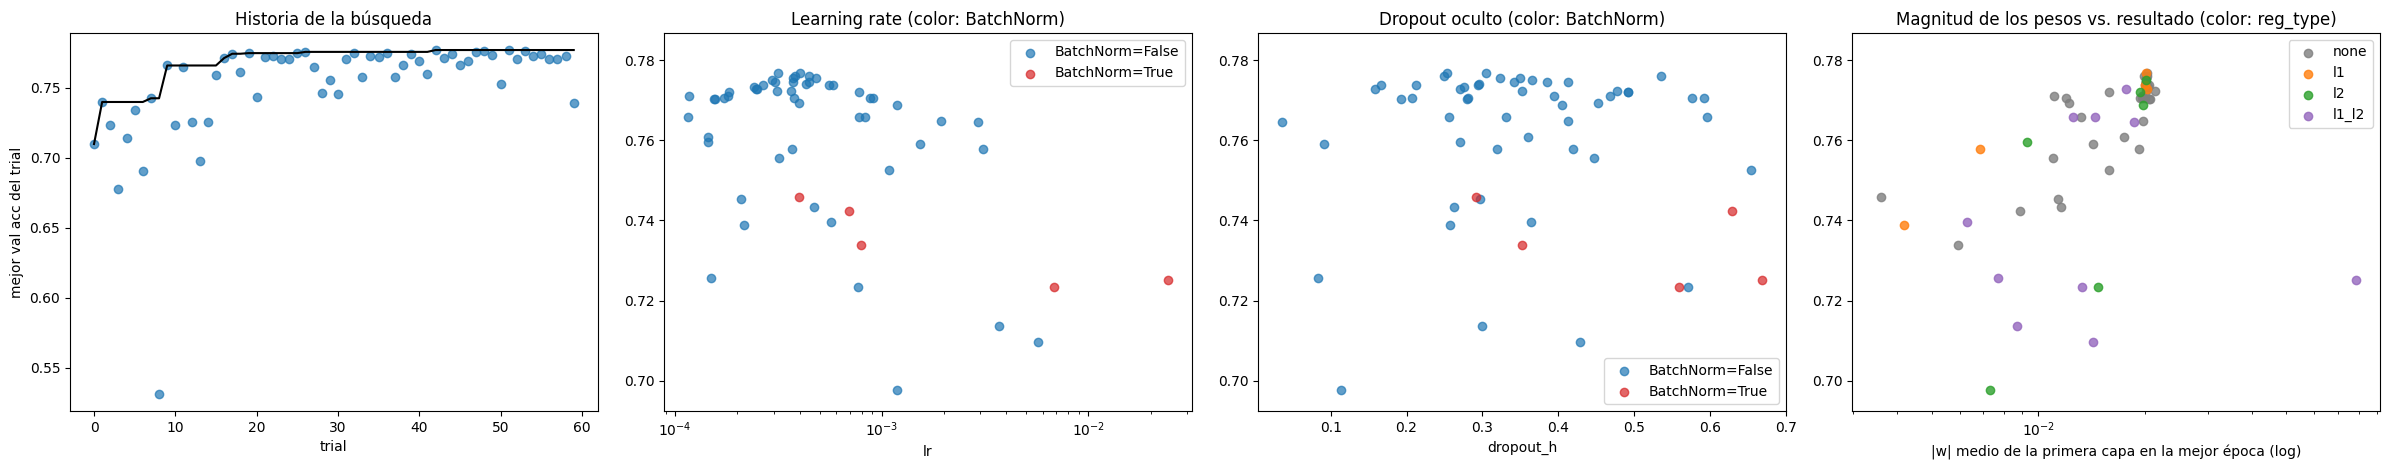

In [ ]:
df_t = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs"))
df_t.columns = [c.replace("params_", "").replace("user_attrs_", "") for c in df_t.columns]
df_t["arch"] = df_t["cfg"].apply(lambda c: "-".join(map(str, c["hidden"])))
df_t["max_norm"] = df_t["max_norm"].astype(int)
show = [c for c in ["number", "value", "best_epoch", "arch", "activation", "lr", "batch_size", "reg_type", "l1", "l2",
                    "dropout_in", "dropout_h", "max_norm", "batchnorm", "wabs_l0", "frac_small", "step_noise", "s_per_epoch"]
        if c in df_t.columns]
fmt = {"value": "{:.4f}".format, "lr": "{:.1e}".format, "l1": "{:.1e}".format, "l2": "{:.1e}".format,
       "dropout_in": "{:.2f}".format, "dropout_h": "{:.2f}".format, "wabs_l0": "{:.2e}".format,
       "frac_small": "{:.2f}".format, "step_noise": "{:.3f}".format, "s_per_epoch": "{:.2f}".format}
best = study.best_value
print(f"Val acc: min {df_t.value.min():.3f} | mediana {df_t.value.median():.3f} | max {best:.3f} | "
      f"trials a < 1 punto del mejor: {(df_t.value >= best - 0.01).sum()}")
print("\nTop 10 trials:")
print(df_t.sort_values("value", ascending=False)[show].head(10).to_string(index=False, formatters=fmt))
print("\nPeores 5 trials:")
print(df_t.sort_values("value")[show].head(5).to_string(index=False, formatters=fmt))

print("\nMediana de la val acc por valor (cantidad de trials):")
for p in ["reg_type", "batchnorm", "max_norm", "n_layers", "activation", "batch_size"]:
    g = df_t.groupby(p)["value"]
    print(f"  {p:10s} " + " | ".join(f"{k}: {v:.3f} ({g.count()[k]})" for k, v in g.median().items()))

complete = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
try:
    imp = optuna.importance.get_param_importances(study, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED))
    print("\nImportancia fANOVA (parámetros presentes en todos los trials):", {k: round(float(v), 2) for k, v in imp.items()})
except Exception as e:
    print("fANOVA no disponible:", type(e).__name__)

fig, axes = plt.subplots(1, 4, figsize=(24, 4.8))
ax = axes[0]
ax.plot(df_t["number"], df_t["value"], "o", alpha=0.7)
ax.plot(df_t["number"], np.maximum.accumulate(df_t["value"].values), color="k")
ax.set_title("Historia de la búsqueda")
ax.set_xlabel("trial")
ax.set_ylabel("mejor val acc del trial")
lo = max(0.3, df_t.value.quantile(0.1) - 0.03)
for ax, col, title in [(axes[1], "lr", "Learning rate (color: BatchNorm)"), (axes[2], "dropout_h", "Dropout oculto (color: BatchNorm)")]:
    for bn, c in [(False, "C0"), (True, "C3")]:
        s = df_t[df_t.batchnorm == bn]
        ax.scatter(s[col], s["value"], color=c, alpha=0.7, label=f"BatchNorm={bn}")
    if col == "lr":
        ax.set_xscale("log")
    ax.set_ylim(lo, best + 0.01)
    ax.set_xlabel(col)
    ax.set_title(title)
    ax.legend()
ax = axes[3]
for r, c in zip(["none", "l1", "l2", "l1_l2"], ["C7", "C1", "C2", "C4"]):
    s = df_t[df_t.reg_type == r]
    ax.scatter(s["wabs_l0"], s["value"], color=c, alpha=0.8, label=r)
ax.set_xscale("log")
ax.set_ylim(lo, best + 0.01)
ax.set_xlabel("|w| medio de la primera capa en la mejor época (log)")
ax.set_title("Magnitud de los pesos vs. resultado (color: reg_type)")
ax.legend()
plt.tight_layout()
plt.show()

### Análisis de la búsqueda

Los 60 trials tardaron 703 s en total. La mejor accuracy de validación fue **0.7768**, y 31 trials quedaron a menos de un punto de ese valor. Como el error estándar de una accuracy de 0.77 con 2.263 documentos es de ~0.009, las diferencias entre los mejores trials no son significativas.

Los 10 mejores trials corresponden prácticamente a la misma configuración, con una capa oculta de 256 unidades, ReLU, batch 128 y un learning rate entre $2.9\cdot10^{-4}$ y $4.8\cdot10^{-4}$. Todos usan dropout en la entrada (entre 0.19 y 0.29) y en la capa oculta (entre 0.25 y 0.54), max-norm 5 y ninguno usa BatchNorm. Ocho de ellos no tienen L1 ni L2, y los otros dos usan $\lambda_1 = 1.8\cdot10^{-9}$ y $\lambda_2 = 10^{-8}$, valores tan chicos que en la práctica no regularizan, ya que el |w| medio de su primera capa es igual al de los trials sin penalización (2.0e-2).

Las medianas por valor de cada hiperparámetro no constituyen comparaciones controladas, porque Optuna prueba con más frecuencia lo que funciona, pero sirven para identificar tendencias. Según el tipo de penalización, la mediana es 0.771 sin penalización (38 trials), 0.773 con L1 (5), 0.764 con L2 (6) y 0.726 con L1+L2 (11). Sin BatchNorm es 0.770 (54 trials) y con BatchNorm 0.730 (6). Con max-norm 5 es 0.771 (46), con 4 es 0.726 (7) y con 3 es 0.706 (4). En cuanto a la profundidad, la mediana pasa de 0.771 con una capa a 0.740 con dos y 0.694 con tres, lo que repite el resultado del TP2.

Según fANOVA, lo que más explica la variación entre trials es el learning rate (0.41), seguido por la cantidad de capas (0.19) y por max-norm (0.13), mientras que el tipo de penalización tiene una importancia de 0.02. En este problema, la regularización explícita de los pesos influye mucho menos que la capacidad del modelo y la velocidad de aprendizaje, algo que la sección 5 verifica de forma controlada.

## 5. Experimentos controlados

La búsqueda varía todos los hiperparámetros a la vez, por lo que sus medianas no permiten aislar el efecto de cada técnica. Para no cambiar varios hiperparámetros al mismo tiempo, se parte de una red sobredimensionada y sin regularizar, que sobreajusta, y se agrega una técnica por vez.

La red base tiene 2 capas ocultas de 512 unidades, ReLU, Adam con $\eta = 10^{-3}$ y batch 128, lo que da unos 21 millones de parámetros para 9.051 documentos. Una red grande es la condición en la que se recomienda aplicar dropout, y también la que permite ver con claridad el efecto de L1 y L2. Cada configuración se entrena 30 épocas sin early stopping, para observar qué ocurre después del mejor punto, y se repite con 3 semillas, que cambian la inicialización, el orden de los batches y las máscaras de dropout. Las tablas informan la media ± el desvío entre semillas y los gráficos muestran la media con una banda de ±1 desvío. Con 2.263 documentos de validación, el error estándar de una accuracy de 0.75 es $\sqrt{0.75\cdot0.25/2263}\approx0.009$, y una diferencia se considera real solo si supera ese error y el desvío entre semillas.

Las columnas de las tablas son las siguientes.

| Columna | Significado |
|---|---|
| `mejor val acc`, `ép.` | Máxima accuracy de validación de cada semilla, promediada, y época en que se alcanza |
| `val acc final`, `val loss final` | Valores en la época 30 |
| `brecha` | Accuracy de train (modo evaluación) menos accuracy de validación, en la época 30 |
| `\|w\| L1`, `\|w\| L3` | Valor absoluto medio de los pesos de la primera capa oculta y de la capa de salida, en la época 30 |
| `% \|w\|<1e-3` | Porcentaje de pesos casi nulos en la primera capa |
| `norma unidad máx` | Mayor norma del vector de pesos que entra a una unidad de la primera capa oculta, que es lo que limita max-norm |
| `ruido pasos` | Ruido relativo de la loss por batch en las últimas 5 épocas |
| `osc. val` | Oscilación de la accuracy de validación de una época a la siguiente, desde la época 10 |
| `train run − eval` | Diferencia entre la accuracy de train medida durante la época (modo entrenamiento) y la medida al final (modo evaluación) |
| `s/época` | Tiempo de una época de entrenamiento |

In [ ]:
EPOCHS_DYN = 3 if MODO_RAPIDO else 30
BASE = {"hidden": [512, 512], "activation": "relu", "lr": 1e-3, "batch_size": 128}
RESULTS = {}      # nombre -> dict con historias por semilla y resumen
_cache = {}


def cfg_key(cfg):
    return tuple(sorted((k, tuple(v) if isinstance(v, list) else v) for k, v in cfg.items()))


def run_config(name, cfg, group):
    key = cfg_key(cfg)
    if key in _cache:
        RESULTS.setdefault(name, _cache[key])
        _cache[key]["groups"].add(group)
        print(f"[{group}] {name:34s} misma configuración que '{_cache[key]['name']}': se reutiliza")
        return _cache[key]
    hs, post = [], None
    for s in SEEDS:
        model, h = train_model(cfg, X_tr, y_tr, X_val, y_val, epochs=EPOCHS_DYN, seed=s)
        if s == SEEDS[0]:
            post = posthoc(model, X_val, y_val)
        hs.append(h)
        del model
    if device.type == "cuda":
        torch.cuda.empty_cache()
    m = lambda f: (float(np.mean([f(h) for h in hs])), float(np.std([f(h) for h in hs])))
    summ = {"mejor val acc": m(lambda h: h["best_val_acc"]), "ép.": m(lambda h: h["best_epoch"]),
            "val acc final": m(lambda h: h["val_acc"][-1]), "val loss mín": m(lambda h: np.nanmin(h["val_loss"])),
            "val loss final": m(lambda h: h["val_loss"][-1]), "brecha": m(lambda h: h["train_acc"][-1] - h["val_acc"][-1]),
            "|w| L1": m(lambda h: h["wabs"][-1][0]), "|w| L3": m(lambda h: h["wabs"][-1][-1]),
            "% |w|<1e-3": m(lambda h: 100 * h["frac_small"][-1]), "norma unidad máx": m(lambda h: h["row_norm_max"]),
            "ruido pasos": m(step_noise),
            "osc. val": m(val_jitter), "train run − eval": m(lambda h: h["run_acc"][-1] - h["train_acc"][-1]),
            "s/época": m(lambda h: np.mean(h["epoch_time"]))}
    rec = {"name": name, "cfg": cfg, "hs": hs, "post": post, "summ": summ, "groups": {group}}
    RESULTS[name] = _cache[key] = rec
    with mlflow.start_run(run_name=f"{group}_{name}"):
        mlflow.log_params({k: str(v) for k, v in cfg.items()})
        mlflow.log_metrics({re.sub(r"[^0-9A-Za-z]+", "_", k).strip("_"): v[0] for k, v in summ.items()})
    s = summ
    print(f"[{group}] {name:34s} mejor val acc {s['mejor val acc'][0]:.4f} ± {s['mejor val acc'][1]:.4f} (ép. {s['ép.'][0]:.0f}) | "
          f"final {s['val acc final'][0]:.4f} | val loss {s['val loss mín'][0]:.3f} → {s['val loss final'][0]:.3f} | "
          f"|w| L1 {s['|w| L1'][0]:.2e} | {s['s/época'][0]:.2f} s/época")
    return rec


def table(names, cols=None):
    cols = cols or ["mejor val acc", "ép.", "val acc final", "val loss mín", "val loss final", "brecha", "|w| L1", "|w| L3",
                    "% |w|<1e-3", "norma unidad máx", "ruido pasos", "osc. val", "train run − eval", "s/época"]
    rows = []
    for n in names:
        s = RESULTS[n]["summ"]
        row = {"configuración": n}
        for c in cols:
            mu, sd = s[c]
            if c in ("mejor val acc", "val acc final"):
                row[c] = f"{mu:.4f} ± {sd:.4f}"
            elif c in ("|w| L1", "|w| L3"):
                row[c] = f"{mu:.2e}"
            elif c in ("ép.", "% |w|<1e-3"):
                row[c] = f"{mu:.1f}"
            else:
                row[c] = f"{mu:.3f}"
        rows.append(row)
    print(pd.DataFrame(rows).to_string(index=False))


def plot_runs(names, title, ordered=True):
    colors = plt.cm.viridis(np.linspace(0, 0.85, len(names))) if ordered else [f"C{i}" for i in range(len(names))]
    fig, axes = plt.subplots(1, 5, figsize=(28, 4.6))
    panels = [("val_acc", "Accuracy de validación"), ("val_loss", "Loss de validación"),
              ("train_acc", "Accuracy de train (modo eval)"), ("wabs0", "|w| medio, primera capa"), ("run_acc", "Accuracy de train durante la época")]
    for (k, t), ax in zip(panels, axes):
        for n, c in zip(names, colors):
            hs = RESULTS[n]["hs"]
            if k == "wabs0":
                arr = np.array([[w[0] for w in h["wabs"]] for h in hs])
            else:
                arr = np.array([h[k] for h in hs])
            ep = np.arange(1, arr.shape[1] + 1)
            mu, sd = arr.mean(0), arr.std(0)
            ax.plot(ep, mu, color=c, label=n)
            ax.fill_between(ep, mu - sd, mu + sd, color=c, alpha=0.15)
        ax.set_title(t)
        ax.set_xlabel("época")
    axes[1].set_yscale("log")
    axes[3].set_yscale("log")
    h_, l_ = axes[0].get_legend_handles_labels()
    fig.legend(h_, l_, loc="upper center", ncol=min(len(l_), 6), bbox_to_anchor=(0.5, 1.12), frameon=False)
    fig.suptitle(title, y=1.2, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


def plot_hists(names, title):
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
    centers = 0.5 * (HIST_BINS[1:] + HIST_BINS[:-1])
    lin = np.linspace(-0.15, 0.15, 121)
    lc = 0.5 * (lin[1:] + lin[:-1])
    for i, n in enumerate(names):
        p = RESULTS[n]["post"]
        axes[0].plot(centers, p["hist_log"], label=n, color=f"C{i}")
        axes[1].plot(lc, p["hist_lin"], label=n, color=f"C{i}")
    axes[0].set_xlabel("log10 |w|")
    axes[0].set_title("Histograma de log10|w|, primera capa (semilla 0, época 30)")
    axes[1].set_yscale("log")
    axes[1].set_xlabel("w")
    axes[1].set_title("Histograma de w, primera capa (escala log en y)")
    for ax in axes:
        ax.set_ylabel("cantidad de pesos")
        ax.legend(fontsize=8)
    fig.suptitle(title, fontsize=12, fontweight="bold", y=1.03)
    plt.tight_layout()
    plt.show()


_ = run_config("base (sin regularización)", BASE, "base")

[base] base (sin regularización)          mejor val acc 0.7419 ± 0.0024 (ép. 5) | final 0.7282 | val loss 0.925 → 1.268 | |w| L1 1.58e-02 | 0.66 s/época


### A. Regularización L2

Se barre $\lambda_2$ con la penalización incluida en el costo (equivalente a `kernel_regularizer=l2(λ)` en Keras) y se compara con el weight decay desacoplado de AdamW, que se recomendó frente a la L2 acoplada con Adam. En ambos casos se regularizan solo los pesos y no los sesgos.

Se espera que un $\lambda_2$ mayor produzca pesos más chicos y un histograma más concentrado en cero, que reduzca el sobreajuste (con una loss de validación que suba menos) y que, si es demasiado grande, el modelo no llegue a ajustar ni siquiera el train.

[A] L2 λ2=1e-07                        mejor val acc 0.7400 ± 0.0035 (ép. 3) | final 0.7231 | val loss 0.937 → 1.291 | |w| L1 1.22e-02 | 0.97 s/época
[A] L2 λ2=1e-06                        mejor val acc 0.7350 ± 0.0036 (ép. 3) | final 0.7135 | val loss 0.944 → 1.288 | |w| L1 7.97e-03 | 0.97 s/época
[A] L2 λ2=1e-05                        mejor val acc 0.7297 ± 0.0032 (ép. 3) | final 0.6920 | val loss 0.962 → 1.332 | |w| L1 4.89e-03 | 0.97 s/época
[A] L2 λ2=0.0001                       mejor val acc 0.7036 ± 0.0040 (ép. 3) | final 0.6702 | val loss 1.038 → 1.327 | |w| L1 3.46e-03 | 0.97 s/época
[A] AdamW wd=0.1                       mejor val acc 0.7413 ± 0.0040 (ép. 3) | final 0.7207 | val loss 0.926 → 1.199 | |w| L1 1.46e-02 | 0.71 s/época
[A] AdamW wd=1                         mejor val acc 0.7394 ± 0.0033 (ép. 3) | final 0.7001 | val loss 0.934 → 1.120 | |w| L1 1.33e-02 | 0.71 s/época
[A] AdamW wd=10                        mejor val acc 0.7100 ± 0.0073 (ép. 24) | final 0.6908 | val l

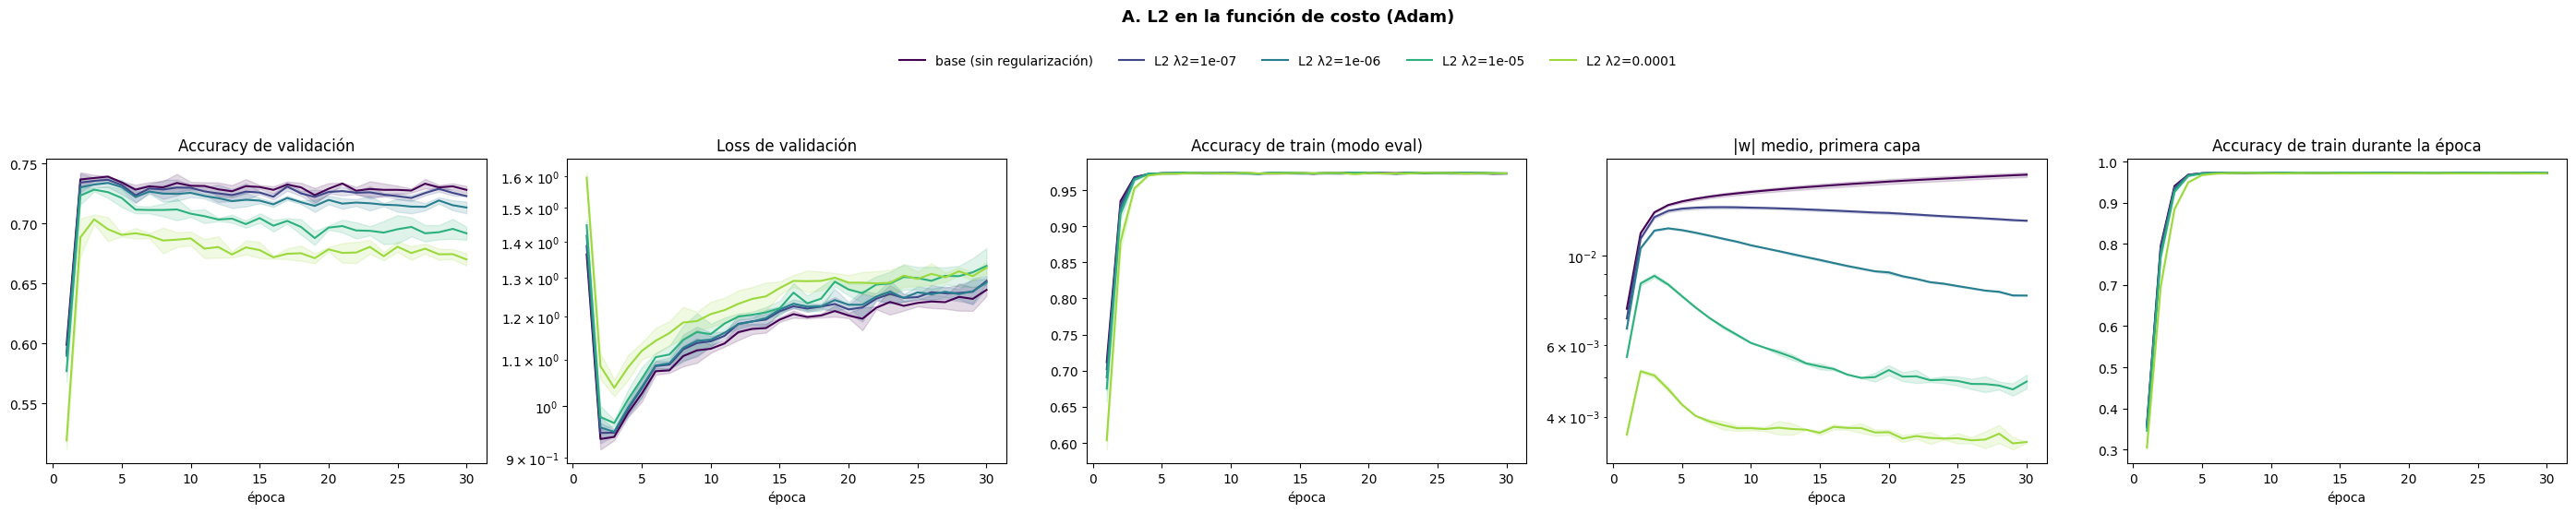

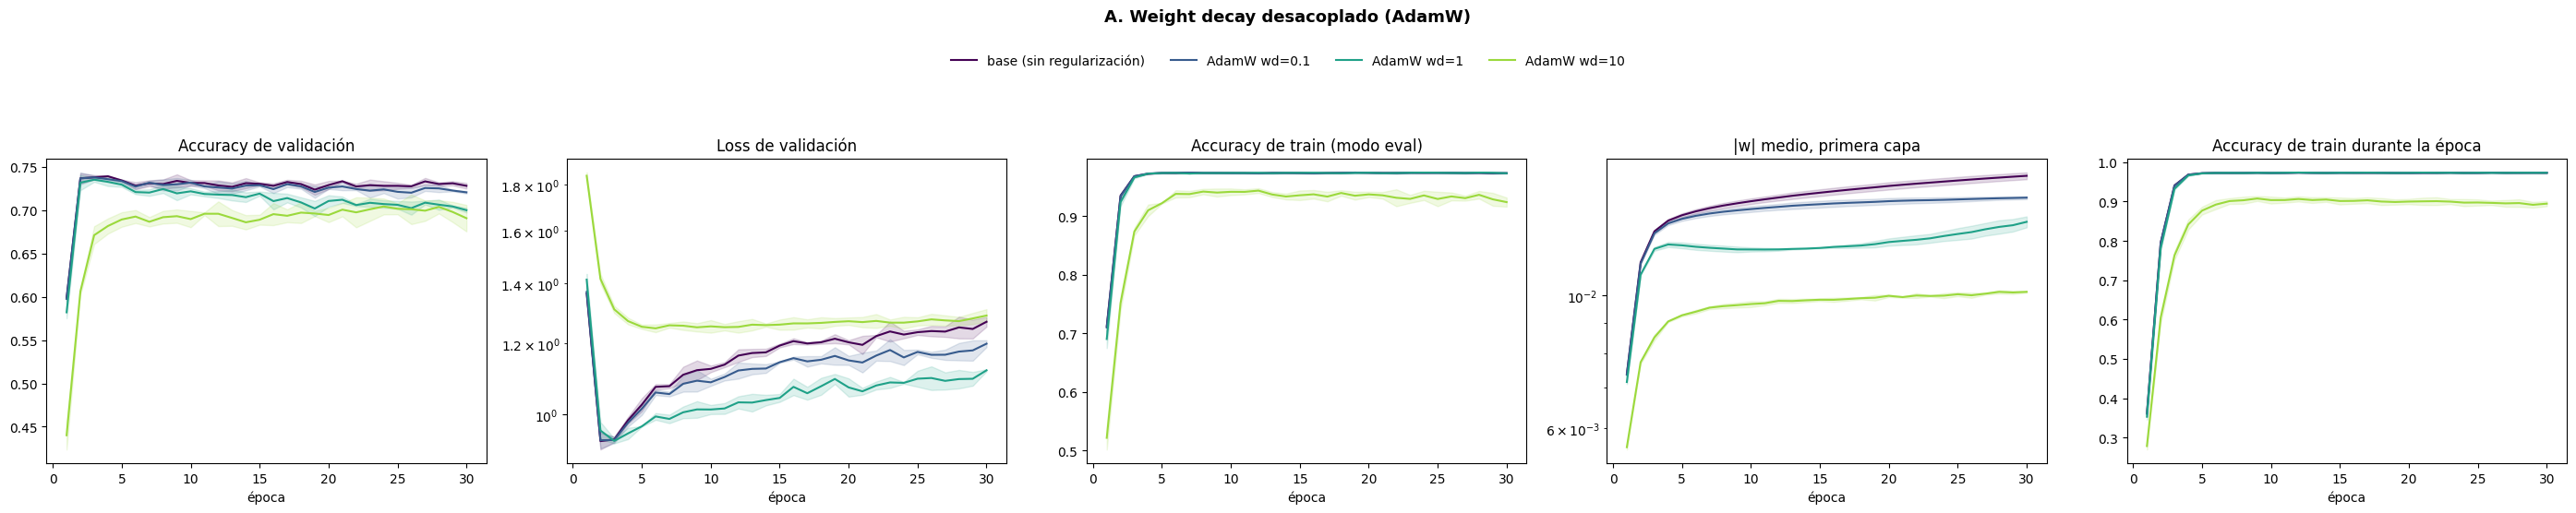

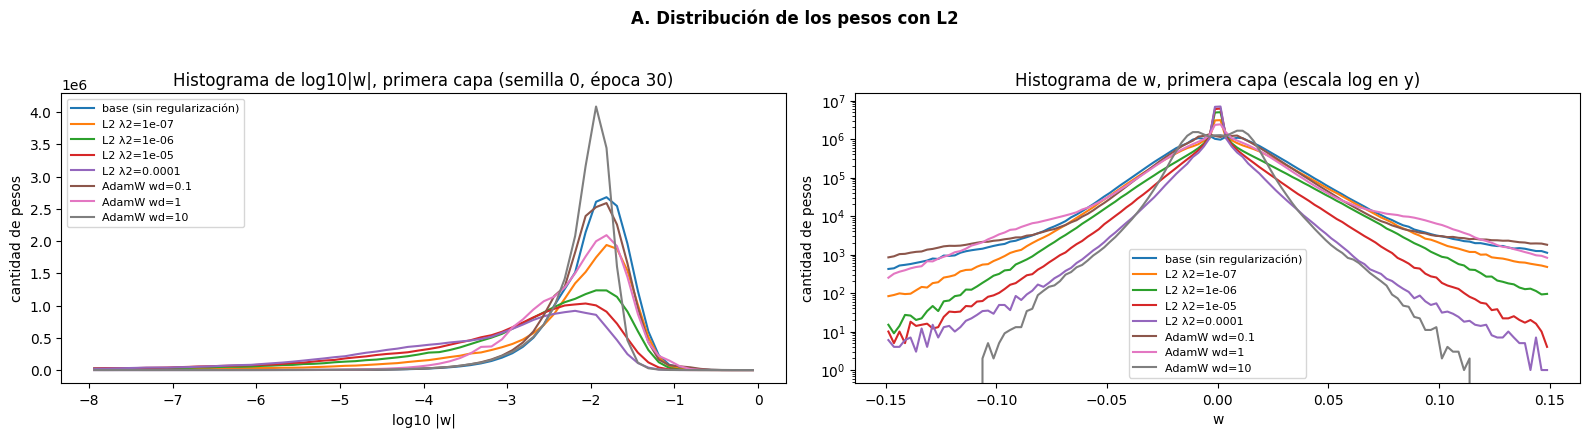

In [ ]:
L2_SWEEP = [1e-7, 1e-6, 1e-5, 1e-4]
WD_SWEEP = [0.1, 1.0, 10.0]
namesA = ["base (sin regularización)"]
for l2 in L2_SWEEP:
    namesA.append(f"L2 λ2={l2:g}")
    run_config(namesA[-1], {**BASE, "l2": l2}, "A")
for wd in WD_SWEEP:
    namesA.append(f"AdamW wd={wd:g}")
    run_config(namesA[-1], {**BASE, "adamw_wd": wd}, "A")
table(namesA)
plot_runs(namesA[:len(L2_SWEEP) + 1], "A. L2 en la función de costo (Adam)")
plot_runs(["base (sin regularización)"] + namesA[len(L2_SWEEP) + 1:], "A. Weight decay desacoplado (AdamW)")
plot_hists(namesA, "A. Distribución de los pesos con L2")

### Análisis A. L2

Con la penalización dentro del costo, los pesos se achican a medida que aumenta $\lambda_2$. El |w| medio de la primera capa pasa de 1.58e-2 a 3.46e-3 con $\lambda_2 = 10^{-4}$, y la mayor norma por unidad baja de 18.6 a 2.6. En el gráfico se observa que, sin regularización, los pesos crecen durante las 30 épocas mientras la loss de validación sube de 0.925 a 1.268, que es el crecimiento de los pesos asociado al sobreajuste. Con L2, en cambio, los pesos alcanzan un máximo y luego se encogen, tanto antes cuanto mayor es $\lambda_2$ (en la época 2 o 3 con $\lambda_2 \geq 10^{-5}$, alrededor de la 5 con $10^{-6}$ y entre la 6 y la 8 con $10^{-7}$).

Sin embargo, la accuracy empeora de forma monótona con $\lambda_2$. La mejor accuracy de validación baja de 0.7419 a 0.7400, 0.7350, 0.7297 y 0.7036, y la final pasa de 0.7282 a 0.6702. La loss de validación sigue subiendo de la misma manera y termina entre 1.29 y 1.33 en todos los casos. La brecha incluso crece, de 0.245 a 0.303, porque la accuracy de train se mantiene en ~0.974 (panel de accuracy de train) mientras la de validación disminuye. Ese valor corresponde al techo de train, ya que en el TP2, con este mismo preprocesamiento, se calculó que la accuracy máxima alcanzable en train es 0.9743 debido a los documentos vacíos o con vectores idénticos de distinta clase.

La columna `% |w|<1e-3` ayuda a interpretar este resultado. Con un $\lambda_2$ de apenas $10^{-7}$, la fracción de pesos casi nulos sube de 3.6 % a 22.3 %, aunque el |w| medio casi no cambia. Una explicación compatible con lo observado es el acoplamiento de la L2 con Adam. El gradiente de la penalización, $2\lambda_2 w$, se divide por el $\sqrt{\hat v}$ de cada peso, y los pesos asociados a palabras raras reciben gradiente de los datos muy pocas veces, por lo que su $\hat v$ es muy chico. Para esos pesos la penalización queda amplificada hasta pasos del orden de $\eta$ y terminan en cero. Así, la L2 acoplada no encogería todos los pesos por igual, sino que eliminaría selectivamente los de las palabras infrecuentes. El contraste con AdamW, que encoge todos los pesos en la misma proporción y casi no genera pesos nulos (5.7 %), apoya esta explicación.

Con weight decay desacoplado (AdamW) y wd = 10, el |w| medio baja a 1.01e-2 y la norma máxima por unidad a 2.8, pero solo el 5.7 % de los pesos queda casi nulo, frente al 57 % de la L2 acoplada, por lo que no hay eliminación selectiva. Con wd = 0.1 el resultado equivale a no regularizar (0.7413). Con wd = 1 se mantiene el máximo (0.7394) y se obtiene la menor loss de validación final del grupo (1.120 frente a 1.268), lo que indica un modelo menos sobreconfiado, aunque la accuracy final baja a 0.7001. Con wd = 10 el aprendizaje se frena, el máximo llega recién en la época 24 y es menor (0.7100).

En cuanto al tiempo, la penalización en el costo agrega un 47 % por época (0.973 s frente a 0.661 s), ya que en cada paso hay que calcular $\sum w^2$ sobre 20,7 millones de pesos y su gradiente. AdamW agrega solo un 8 %, porque el encogimiento es una operación más dentro del paso del optimizador. El ruido paso a paso disminuye con $\lambda_2$ grandes (de 0.51 a 0.38), porque la loss de train deja de llegar a valores casi nulos en algunos batches, mientras que la oscilación de la validación no cambia (entre 0.006 y 0.007).

### B. Regularización L1 y esparcidad

Se barre $\lambda_1$. Además de las curvas, la tabla de poda muestra para la semilla 0 qué fracción de los pesos de la primera capa queda en cero al eliminar los que tienen |w| por debajo de cada umbral, y qué accuracy de validación se obtiene después de la poda.

Con L1 se espera encontrar muchos pesos muy cercanos a cero junto con otros de valor alto, y que la poda afecte mucho menos a la red con L1 que a la red sin regularizar o con L2.

[B] L1 λ1=1e-08                        mejor val acc 0.7368 ± 0.0048 (ép. 3) | final 0.7212 | val loss 0.939 → 1.301 | |w| L1 9.53e-03 | 0.93 s/época
[B] L1 λ1=1e-07                        mejor val acc 0.7335 ± 0.0023 (ép. 4) | final 0.7029 | val loss 0.954 → 1.359 | |w| L1 4.85e-03 | 0.92 s/época
[B] L1 λ1=1e-06                        mejor val acc 0.7135 ± 0.0046 (ép. 4) | final 0.6724 | val loss 1.009 → 1.700 | |w| L1 2.85e-03 | 0.92 s/época
[B] L1 λ1=1e-05                        mejor val acc 0.6602 ± 0.0086 (ép. 11) | final 0.6515 | val loss 1.232 → 1.656 | |w| L1 8.36e-04 | 0.92 s/época
            configuración   mejor val acc  ép.   val acc final val loss mín val loss final brecha   |w| L1   |w| L3 % |w|<1e-3 norma unidad máx ruido pasos osc. val train run − eval s/época
base (sin regularización) 0.7419 ± 0.0024  4.7 0.7282 ± 0.0032        0.925          1.268  0.245 1.58e-02 5.92e-02        3.6           18.603       0.513    0.006           -0.000   0.661
              L1 λ1

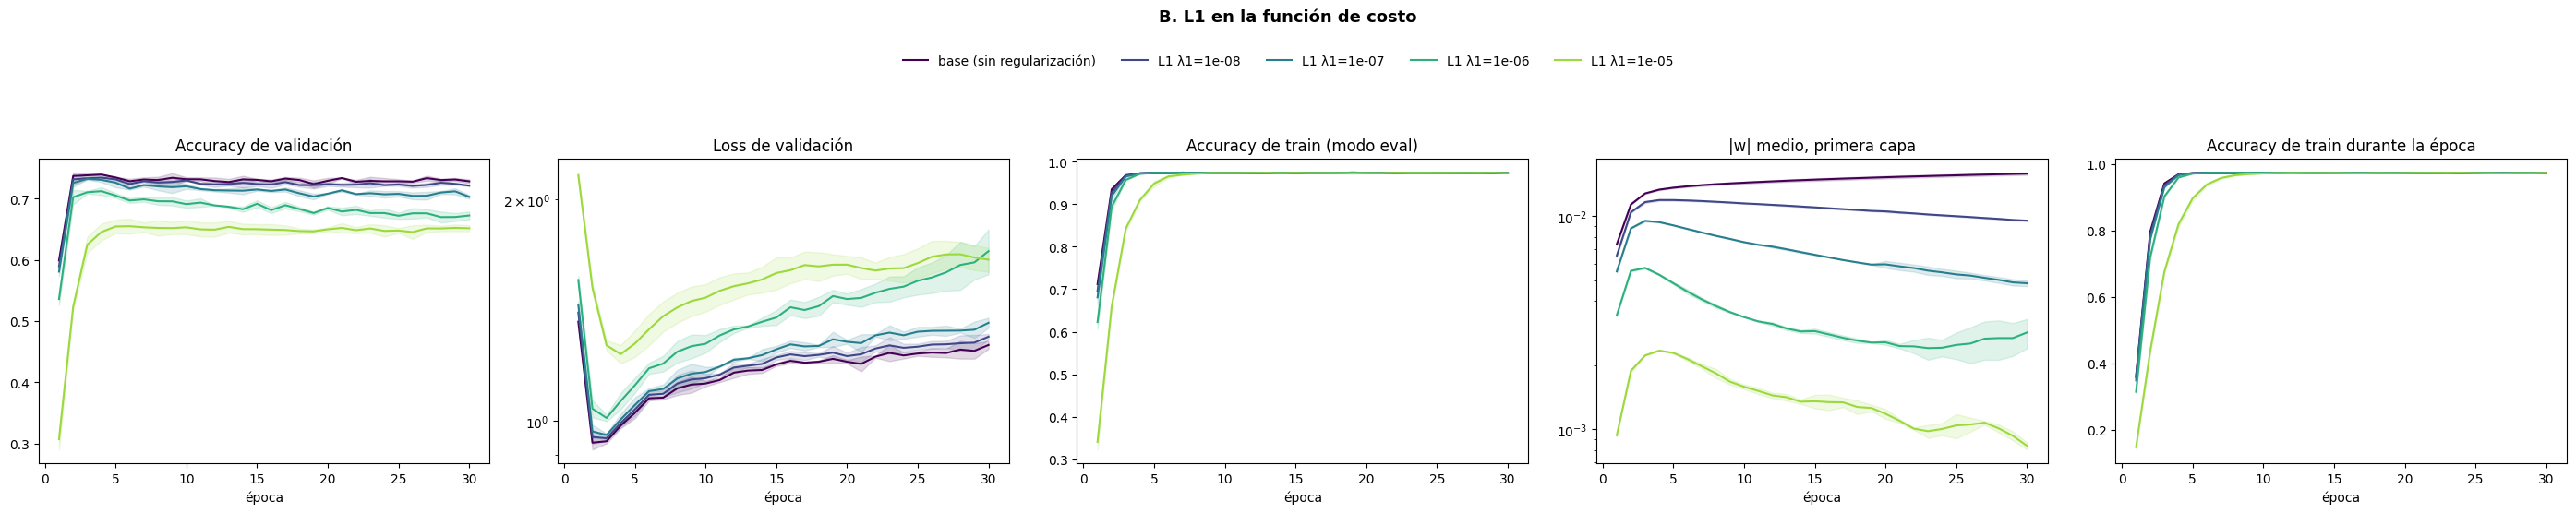

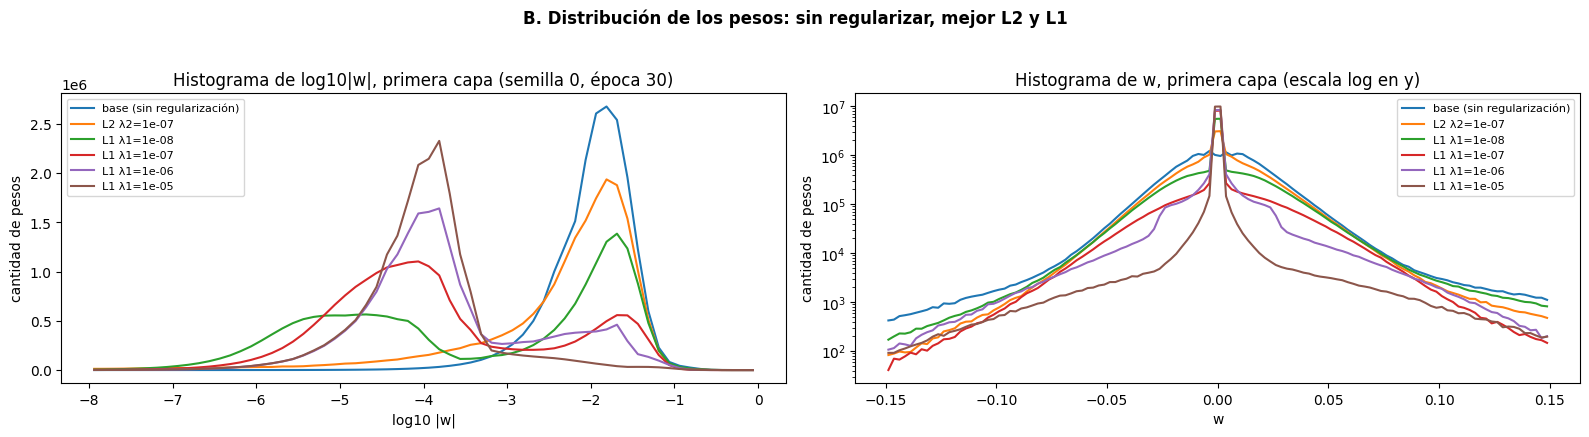

Prueba de poda de la primera capa (semilla 0, época 30):
            configuración umbral % pesos podados val acc después de podar val acc sin podar
base (sin regularización)  1e-04             0.3                   0.7251            0.7251
base (sin regularización)  3e-04             1.1                   0.7251            0.7251
base (sin regularización)  1e-03             3.6                   0.7251            0.7251
base (sin regularización)  3e-03            11.8                   0.7251            0.7251
base (sin regularización)  1e-02            41.4                   0.7256            0.7251
base (sin regularización)  3e-02            87.7                   0.7119            0.7251
              L2 λ2=1e-07  1e-04            12.8                   0.7234            0.7234
              L2 λ2=1e-07  3e-04            16.3                   0.7234            0.7234
              L2 λ2=1e-07  1e-03            22.3                   0.7234            0.7234
              L2 λ2=1e-

In [ ]:
L1_SWEEP = [1e-8, 1e-7, 1e-6, 1e-5]
namesB = ["base (sin regularización)"]
for l1 in L1_SWEEP:
    namesB.append(f"L1 λ1={l1:g}")
    run_config(namesB[-1], {**BASE, "l1": l1}, "B")
table(namesB)
plot_runs(namesB, "B. L1 en la función de costo")


def best_by_val(names):
    return max(names, key=lambda n: RESULTS[n]["summ"]["mejor val acc"][0])


best_l2_name = best_by_val([n for n in namesA if n.startswith("L2")])
best_l1_name = best_by_val([n for n in namesB if n.startswith("L1")])
compare_prune = ["base (sin regularización)", best_l2_name] + [n for n in namesB if n.startswith("L1")]
plot_hists(compare_prune, "B. Distribución de los pesos: sin regularizar, mejor L2 y L1")
rows = []
for n in compare_prune:
    for thr, frac, acc in RESULTS[n]["post"]["prune"]:
        rows.append({"configuración": n, "umbral": thr, "% pesos podados": 100 * frac, "val acc después de podar": acc})
pr = pd.DataFrame(rows)
base_acc = {n: RESULTS[n]["hs"][0]["val_acc"][-1] for n in compare_prune}
pr["val acc sin podar"] = pr["configuración"].map(base_acc)
print("Prueba de poda de la primera capa (semilla 0, época 30):")
print(pr.to_string(index=False, formatters={"umbral": "{:.0e}".format, "% pesos podados": "{:.1f}".format,
                                             "val acc después de podar": "{:.4f}".format, "val acc sin podar": "{:.4f}".format}))

### Análisis B. L1

L1 produce la distribución esperada. El histograma de log10|w| se vuelve bimodal, con un grupo de pesos útiles alrededor de 1e-2 y otro grupo de pesos apagados alrededor de 1e-4 a 1e-5 que crece con $\lambda_1$. La fracción de pesos con |w| < 1e-3 pasa de 3.6 % sin regularizar a 50.5, 75.8, 81.1 y 93.7 % para $\lambda_1 = 10^{-8}, 10^{-7}, 10^{-6}$ y $10^{-5}$. Con Adam, los pesos apagados no quedan exactamente en cero, porque el gradiente $\lambda_1\,\text{sign}(w)$ normalizado por el optimizador los hace oscilar alrededor de cero con una amplitud del orden del paso. Por eso el segundo pico se ubica en 1e-4 a 1e-5 y no en 0.

La prueba de poda confirma esa esparcidad. Con $\lambda_1 = 10^{-5}$ se pueden anular los pesos con |w| < 1e-2, que son el 98.5 % de la primera capa, sin que baje la accuracy de validación (0.6522 frente a 0.6491 sin podar), y lo mismo ocurre al podar el 99.3 % (0.6562). Con $\lambda_1 = 10^{-7}$ se poda el 79.6 % sin cambios (0.6991 frente a 0.6986). La red sin regularizar también admite podar el 41 % de los pesos (umbral 1e-2) sin pérdidas, porque los pesos de las palabras que casi no aparecen en train permanecen cerca de su valor inicial (la inicialización por defecto de PyTorch para una capa `Linear` es uniforme en $\pm 1/\sqrt{40000} = \pm 0.005$). Con el umbral 3e-2, en cambio, la red sin regularizar pierde 1.3 puntos al podar el 87.7 %, y las redes con $\lambda_1$ de $10^{-8}$ y $10^{-7}$ pierden lo mismo (1.5 y 1.4 puntos). Solo con $\lambda_1 \geq 10^{-6}$ la poda no cuesta accuracy (−0.2 y +0.7 puntos, con el 97.6 % y el 99.3 % de los pesos podados). En la práctica, L1 realiza una selección del vocabulario, y la red con $\lambda_1 = 10^{-5}$ utiliza menos del 2 % de los pesos de su primera capa.

El costo de esta esparcidad es la accuracy. La mejor accuracy de validación baja de 0.7419 a 0.7368, 0.7335, 0.7135 y 0.6602, y la final de 0.7282 a 0.6515. Como con L2, la brecha crece (de 0.245 a 0.321) y la loss de validación final sube más que sin regularizar, hasta 1.70. L1 apaga las palabras con poco gradiente, que son las menos frecuentes, y con 9.051 documentos muchas palabras discriminativas aparecen pocas veces, por lo que perderlas cuesta más de lo que se gana en varianza. En tiempo, L1 agrega un 40 % por época (0.925 s) por el mismo motivo que L2.

### C. L1+L2

Se combinan el mejor $\lambda_1$ y el mejor $\lambda_2$ de los barridos anteriores (elegidos por validación), y también la combinación con los dos valores divididos por 3, para que la penalización total no sea simplemente la suma de dos penalizaciones ya óptimas.

[C] L1+L2 λ1=1e-08 λ2=1e-07            mejor val acc 0.7368 ± 0.0045 (ép. 3) | final 0.7204 | val loss 0.942 → 1.293 | |w| L1 9.04e-03 | 1.24 s/época
[C] L1+L2 λ1=3e-09 λ2=3e-08            mejor val acc 0.7372 ± 0.0053 (ép. 3) | final 0.7231 | val loss 0.936 → 1.299 | |w| L1 1.11e-02 | 1.24 s/época
            configuración   mejor val acc ép.   val acc final val loss mín val loss final brecha   |w| L1   |w| L3 % |w|<1e-3 norma unidad máx ruido pasos osc. val train run − eval s/época
base (sin regularización) 0.7419 ± 0.0024 4.7 0.7282 ± 0.0032        0.925          1.268  0.245 1.58e-02 5.92e-02        3.6           18.603       0.513    0.006           -0.000   0.661
              L1 λ1=1e-08 0.7368 ± 0.0048 2.7 0.7212 ± 0.0010        0.939          1.301  0.252 9.53e-03 4.66e-02       50.5           12.624       0.513    0.005           -0.000   0.925
              L2 λ2=1e-07 0.7400 ± 0.0035 2.7 0.7231 ± 0.0004        0.937          1.291  0.250 1.22e-02 4.91e-02       22.3        

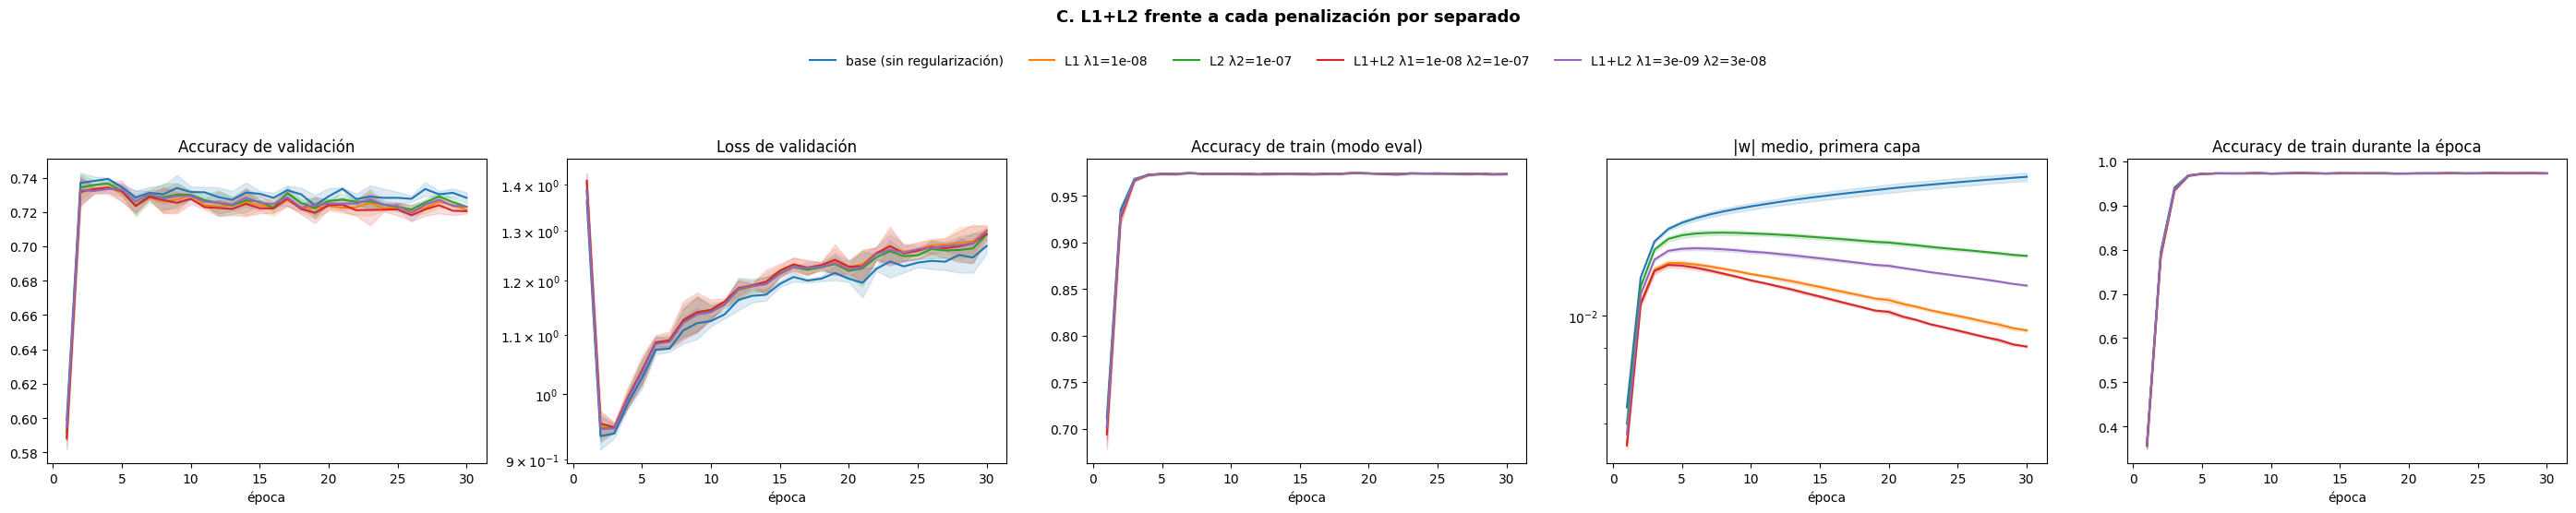

In [ ]:
l1s, l2s = RESULTS[best_l1_name]["cfg"]["l1"], RESULTS[best_l2_name]["cfg"]["l2"]
namesC = ["base (sin regularización)", best_l1_name, best_l2_name]
for f in [1, 3]:
    namesC.append(f"L1+L2 λ1={l1s / f:.1g} λ2={l2s / f:.1g}")
    run_config(namesC[-1], {**BASE, "l1": l1s / f, "l2": l2s / f}, "C")
table(namesC)
plot_runs(namesC, "C. L1+L2 frente a cada penalización por separado", ordered=False)

### Análisis C. L1+L2

Las dos combinaciones dan el mismo resultado que L1 sola, con 0.7368 y 0.7372 frente a 0.7368 de L1 con $\lambda_1 = 10^{-8}$ y 0.7400 de L2 con $\lambda_2 = 10^{-7}$. Las diferencias son de décimas de punto, dentro del desvío entre semillas (~0.005), y tanto el histograma como la fracción de pesos casi nulos (entre 39 y 51 %) quedan dominados por L1.

Como ninguna de las dos penalizaciones mejora el modelo por separado, su combinación tampoco lo hace, y además cuesta casi el doble de tiempo (1.241 s por época, un 88 % más), porque se calculan ambas penalizaciones sobre todos los pesos.

### D. Dropout, dropout en la entrada y max-norm

Se prueban de a una las recomendaciones para el dropout. Se varía la tasa de dropout en las capas ocultas (20 %, 50 % y 70 %), se agrega dropout en la entrada (20 %) y se aplica max-norm 3 sobre los pesos de las capas ocultas, un valor algo más restrictivo que el recomendado (del orden de 4 o 5). El efecto de subir el learning rate con dropout se estudia en el experimento E. Max-norm solo actúa si alguna unidad supera la norma $c$, y como esa norma depende de la cantidad de entradas de cada unidad (40.000 en la primera capa), también se prueba $c = 1$. La columna `norma unidad máx` permite verificar si la restricción estuvo activa. El último gráfico muestra la loss de cada batch de la semilla 0 en las últimas épocas, para observar el ruido de la curva de entrenamiento.

[D] dropout 0.2                        mejor val acc 0.7409 ± 0.0020 (ép. 6) | final 0.7297 | val loss 0.929 → 1.275 | |w| L1 1.63e-02 | 0.66 s/época
[D] dropout 0.5                        mejor val acc 0.7434 ± 0.0008 (ép. 8) | final 0.7318 | val loss 0.921 → 1.318 | |w| L1 1.74e-02 | 0.66 s/época
[D] dropout 0.7                        mejor val acc 0.7492 ± 0.0022 (ép. 7) | final 0.7334 | val loss 0.914 → 1.347 | |w| L1 1.89e-02 | 0.66 s/época
[D] dropout 0.5 + entrada 0.2          mejor val acc 0.7422 ± 0.0008 (ép. 7) | final 0.7332 | val loss 0.915 → 1.322 | |w| L1 1.96e-02 | 0.68 s/época
[D] dropout 0.5 + entrada 0.2 + max-norm 3 mejor val acc 0.7411 ± 0.0012 (ép. 5) | final 0.7117 | val loss 0.913 → 1.191 | |w| L1 1.04e-02 | 0.80 s/época
[D] max-norm 3 (sin dropout)           mejor val acc 0.7411 ± 0.0031 (ép. 3) | final 0.7197 | val loss 0.925 → 1.200 | |w| L1 1.12e-02 | 0.78 s/época
[D] max-norm 1 (sin dropout)           mejor val acc 0.6910 ± 0.0069 (ép. 5) | final 0.6478 | va

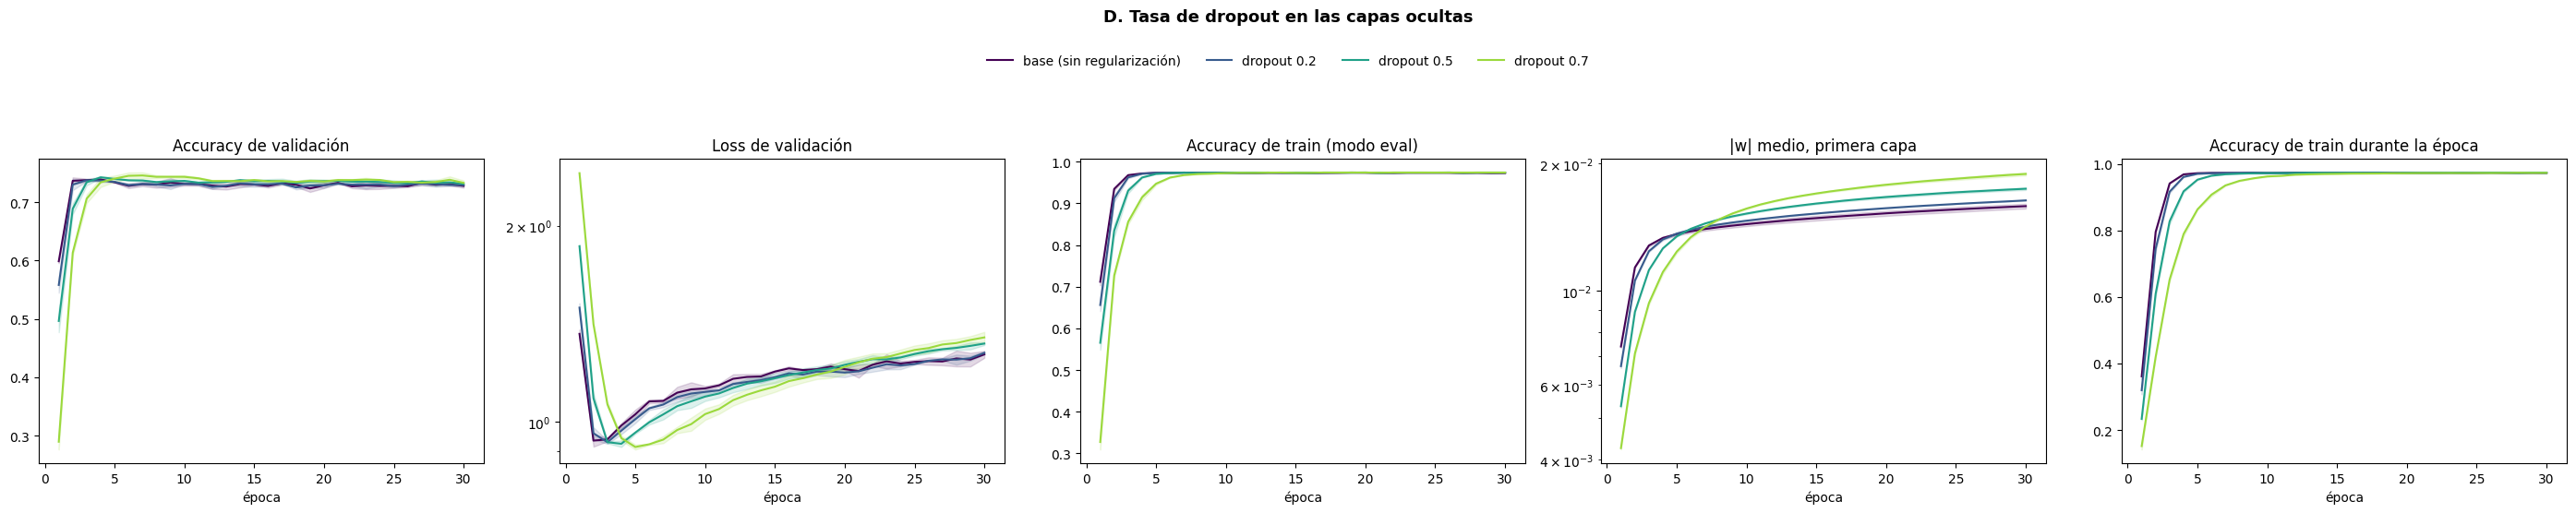

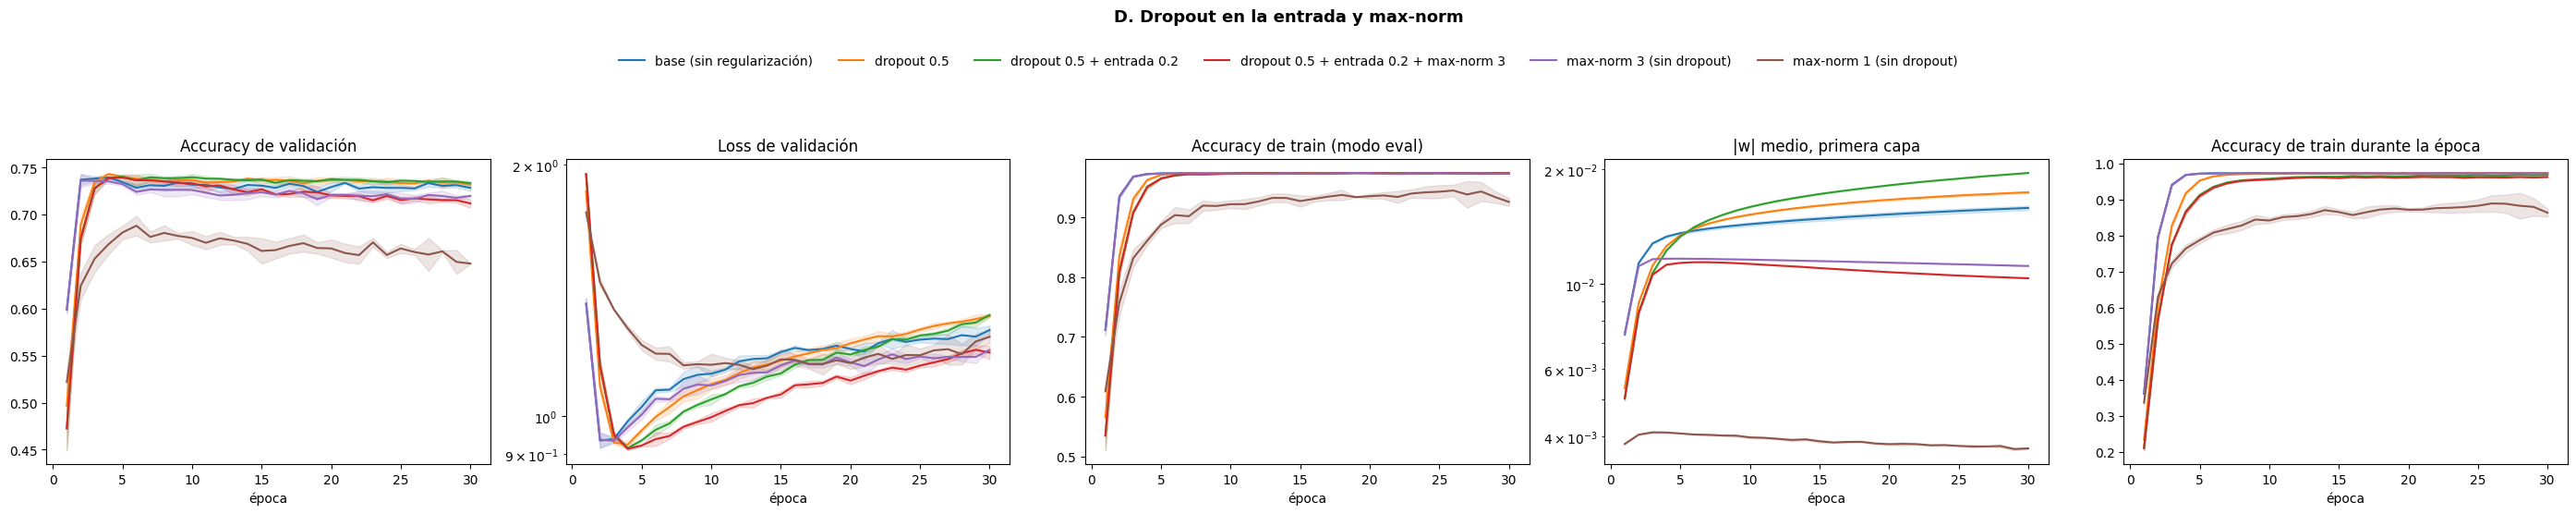

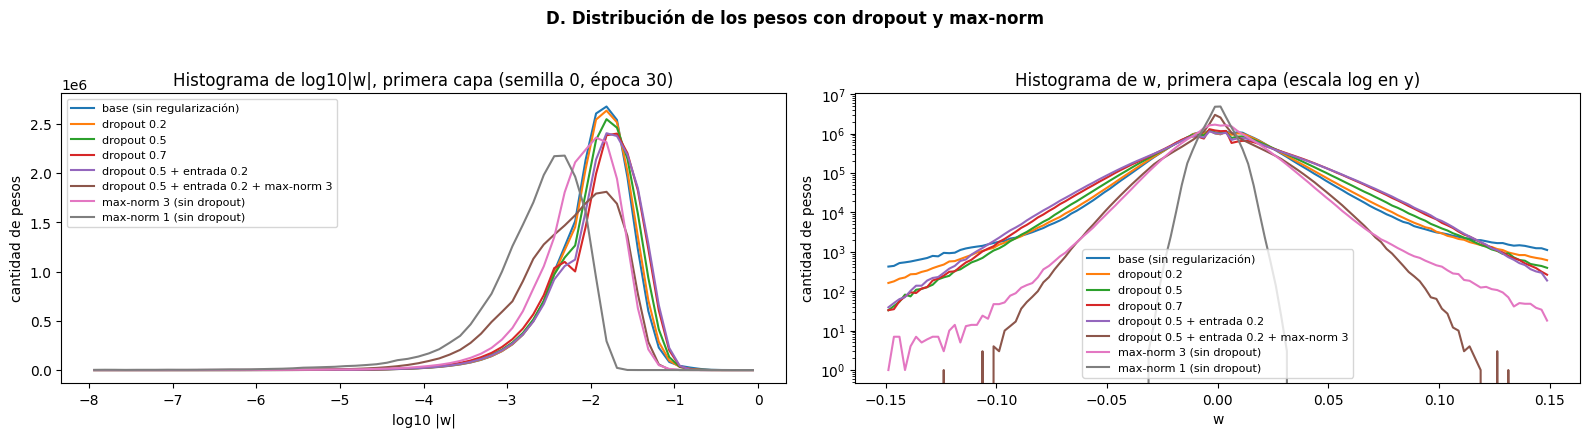

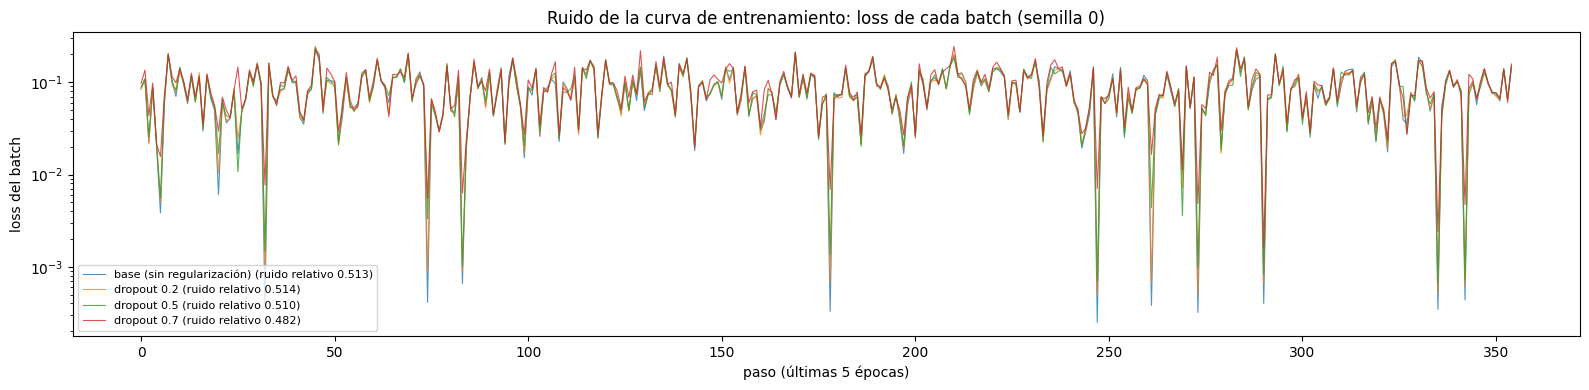

In [ ]:
namesD = ["base (sin regularización)"]
for p in [0.2, 0.5, 0.7]:
    namesD.append(f"dropout {p:g}")
    run_config(namesD[-1], {**BASE, "dropout_h": p}, "D")
namesD.append("dropout 0.5 + entrada 0.2")
run_config(namesD[-1], {**BASE, "dropout_h": 0.5, "dropout_in": 0.2}, "D")
namesD.append("dropout 0.5 + entrada 0.2 + max-norm 3")
run_config(namesD[-1], {**BASE, "dropout_h": 0.5, "dropout_in": 0.2, "max_norm": 3}, "D")
namesD.append("max-norm 3 (sin dropout)")
run_config(namesD[-1], {**BASE, "max_norm": 3}, "D")
namesD.append("max-norm 1 (sin dropout)")
run_config(namesD[-1], {**BASE, "max_norm": 1}, "D")
table(namesD)
plot_runs(namesD[:4], "D. Tasa de dropout en las capas ocultas")
plot_runs(["base (sin regularización)", "dropout 0.5", "dropout 0.5 + entrada 0.2", "dropout 0.5 + entrada 0.2 + max-norm 3",
           "max-norm 3 (sin dropout)", "max-norm 1 (sin dropout)"], "D. Dropout en la entrada y max-norm", ordered=False)
plot_hists(namesD, "D. Distribución de los pesos con dropout y max-norm")

fig, ax = plt.subplots(figsize=(16, 4))
for i, n in enumerate(["base (sin regularización)", "dropout 0.2", "dropout 0.5", "dropout 0.7"]):
    sl = np.concatenate(RESULTS[n]["hs"][0]["step_loss"][-5:])
    ax.plot(sl, lw=0.8, alpha=0.8, color=f"C{i}", label=f"{n} (ruido relativo {RESULTS[n]['summ']['ruido pasos'][0]:.3f})")
ax.set_yscale("log")
ax.set_xlabel("paso (últimas 5 épocas)")
ax.set_ylabel("loss del batch")
ax.set_title("Ruido de la curva de entrenamiento: loss de cada batch (semilla 0)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Análisis D. dropout y max-norm

El dropout es la única técnica de la sección 5 que mejora la mejor accuracy de validación.

| | sin dropout | 0.2 | 0.5 | 0.7 |
|---|---|---|---|---|
| mejor val acc | 0.7419 ± 0.0024 | 0.7409 ± 0.0020 | 0.7434 ± 0.0008 | 0.7492 ± 0.0022 |
| mejor época | 4.7 | 6.3 | 8.3 | 6.7 |
| norma máx. por unidad | 18.6 | 14.6 | 9.8 | 7.4 |

La mejora obtenida con una tasa de 0.7 (0.7 puntos) supera el desvío entre semillas, pero es menor que el error estándar de la validación (~0.9 puntos), por lo que se trata de una mejora chica. Además, 0.7 está fuera del rango recomendado (entre 20 % y 50 %), y dentro de ese rango la mejora es nula (0.2) o de 0.15 puntos (0.5). Con dropout el máximo se alcanza más tarde, porque en cada paso se entrena una subred distinta y el aprendizaje es más lento. Los pesos no se achican. El |w| medio de la primera capa aumenta levemente (de 1.58e-2 a 1.89e-2) y el de la capa de salida bastante más (de 5.9e-2 a 9.8e-2), mientras que lo que baja es la norma máxima por unidad, de 18.6 a 7.4. A diferencia de L2, el dropout no limita el tamaño de los pesos, sino que reparte la información entre más unidades para que ninguna resulte imprescindible. Aun así, la loss de validación sigue subiendo al final del entrenamiento (entre 1.27 y 1.35), de modo que el dropout no evita el sobreajuste en 30 épocas.

Agregar dropout en la entrada (0.2) al dropout oculto de 0.5 no modifica el máximo (0.7422). Max-norm 3 está activa, ya que la norma máxima queda exactamente en 3.000 frente a 18.6 sin restricción. No mejora el máximo (0.7411), pero reduce la loss de validación final (1.200 frente a 1.268), lo que indica que limita cuánto puede crecer la confianza de cada unidad. Combinada con ambos dropouts produce la menor loss final del grupo (1.191), aunque la accuracy final baja a 0.7117. Max-norm 1 resulta demasiado restrictiva y lleva la accuracy a 0.6910.

Se esperaba que la accuracy de train fuera más ruidosa con dropout, pero no se observa ese efecto. La diferencia entre la accuracy de train medida durante la época y la medida en modo evaluación es prácticamente nula con cualquier tasa, porque con 21 millones de parámetros la red alcanza el techo de train (0.974) aunque se apague el 70 % de las unidades. El gráfico de la loss por batch muestra el mismo patrón para todas las tasas, lo que sugiere que ese ruido proviene de la composición de los batches (todas las corridas los recorren en el mismo orden) y no del dropout. Los picos hacia abajo corresponden a batches en los que la red acierta todos los documentos con mucha confianza. El efecto del dropout sí aparece en la curva de validación, cuya oscilación baja de 0.006 sin dropout a 0.003 con una tasa de 0.7.

En cuanto al tiempo, el dropout prácticamente no tiene costo (0.661 s por época, igual que sin dropout) y el dropout en la entrada agrega un 3 %. Max-norm agrega un 18 %, porque después de cada paso hay que recalcular la norma de cada fila de las matrices de pesos.

### E. BatchNormalization y learning rate

Se barre el learning rate ($10^{-3}$, $3\cdot10^{-3}$ y $10^{-2}$) en tres variantes de la red base, sin regularizar, con BatchNorm y con dropout 0.5. De esta manera se pueden evaluar a la vez dos recomendaciones, que BatchNorm permite learning rates más altos y que conviene subir el learning rate al usar dropout. También se prueba BatchNorm junto con dropout, combinación que no se suele usar.

[E] base (sin regularización)          misma configuración que 'base (sin regularización)': se reutiliza
[E] BatchNorm lr=0.001                 mejor val acc 0.7434 ± 0.0013 (ép. 5) | final 0.7375 | val loss 0.929 → 1.072 | |w| L1 9.89e-03 | 0.67 s/época
[E] dropout 0.5                        misma configuración que 'dropout 0.5': se reutiliza
[E] sin regularizar lr=0.003           mejor val acc 0.7388 ± 0.0029 (ép. 15) | final 0.7310 | val loss 0.984 → 1.480 | |w| L1 2.49e-02 | 0.66 s/época
[E] BatchNorm lr=0.003                 mejor val acc 0.7344 ± 0.0057 (ép. 13) | final 0.7222 | val loss 0.953 → 1.363 | |w| L1 3.49e-02 | 0.67 s/época
[E] dropout 0.5 lr=0.003               mejor val acc 0.7449 ± 0.0027 (ép. 9) | final 0.7313 | val loss 0.919 → 1.522 | |w| L1 3.00e-02 | 0.66 s/época
[E] sin regularizar lr=0.01            mejor val acc 0.7266 ± 0.0045 (ép. 2) | final 0.6941 | val loss 0.991 → 1.907 | |w| L1 5.86e-02 | 0.66 s/época
[E] BatchNorm lr=0.01                  mejor val acc

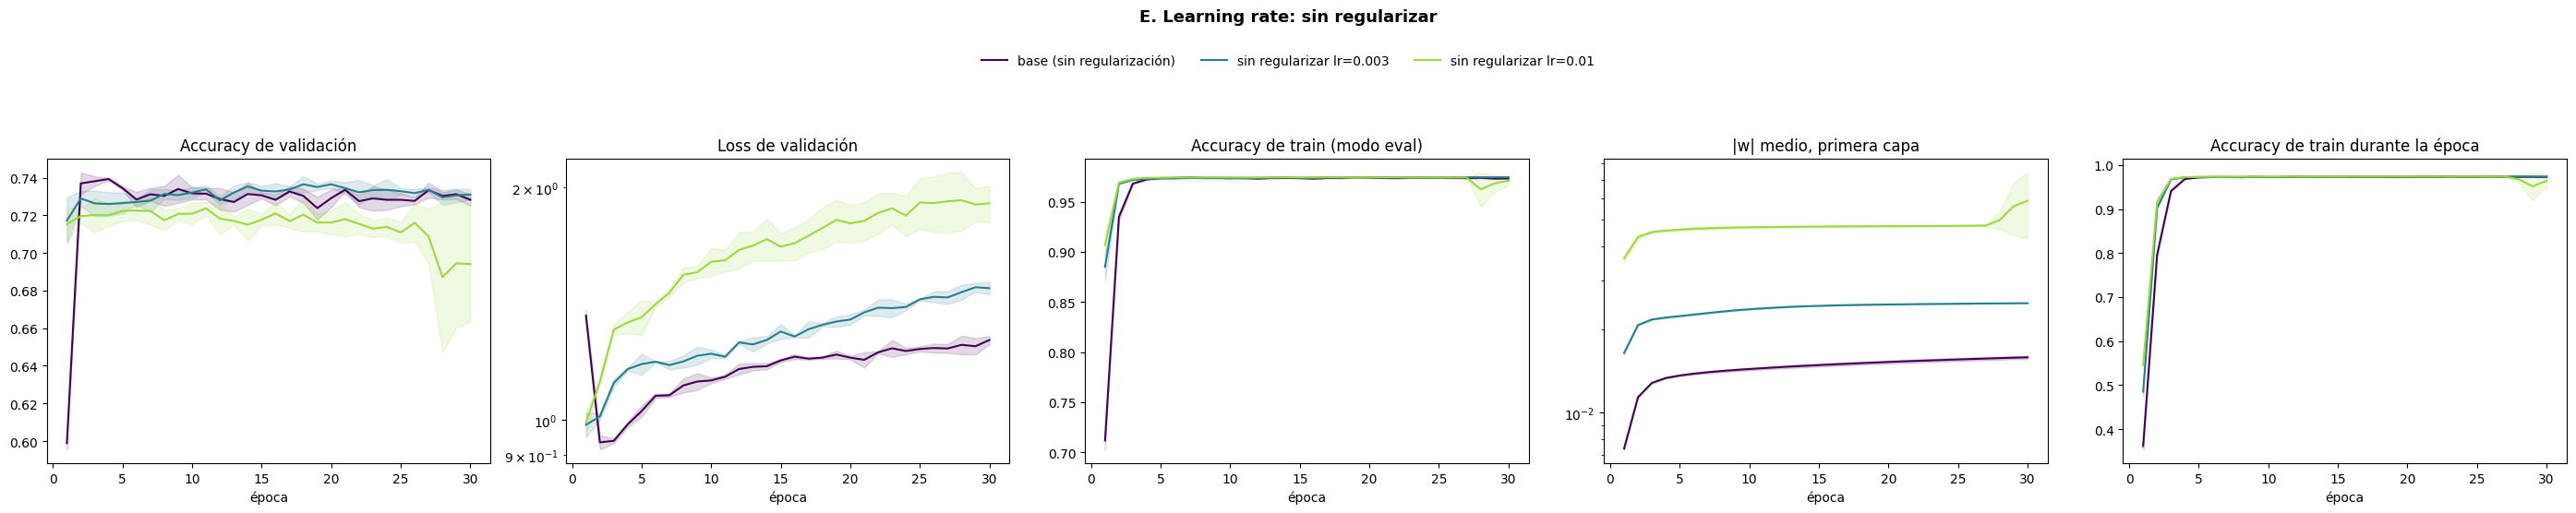

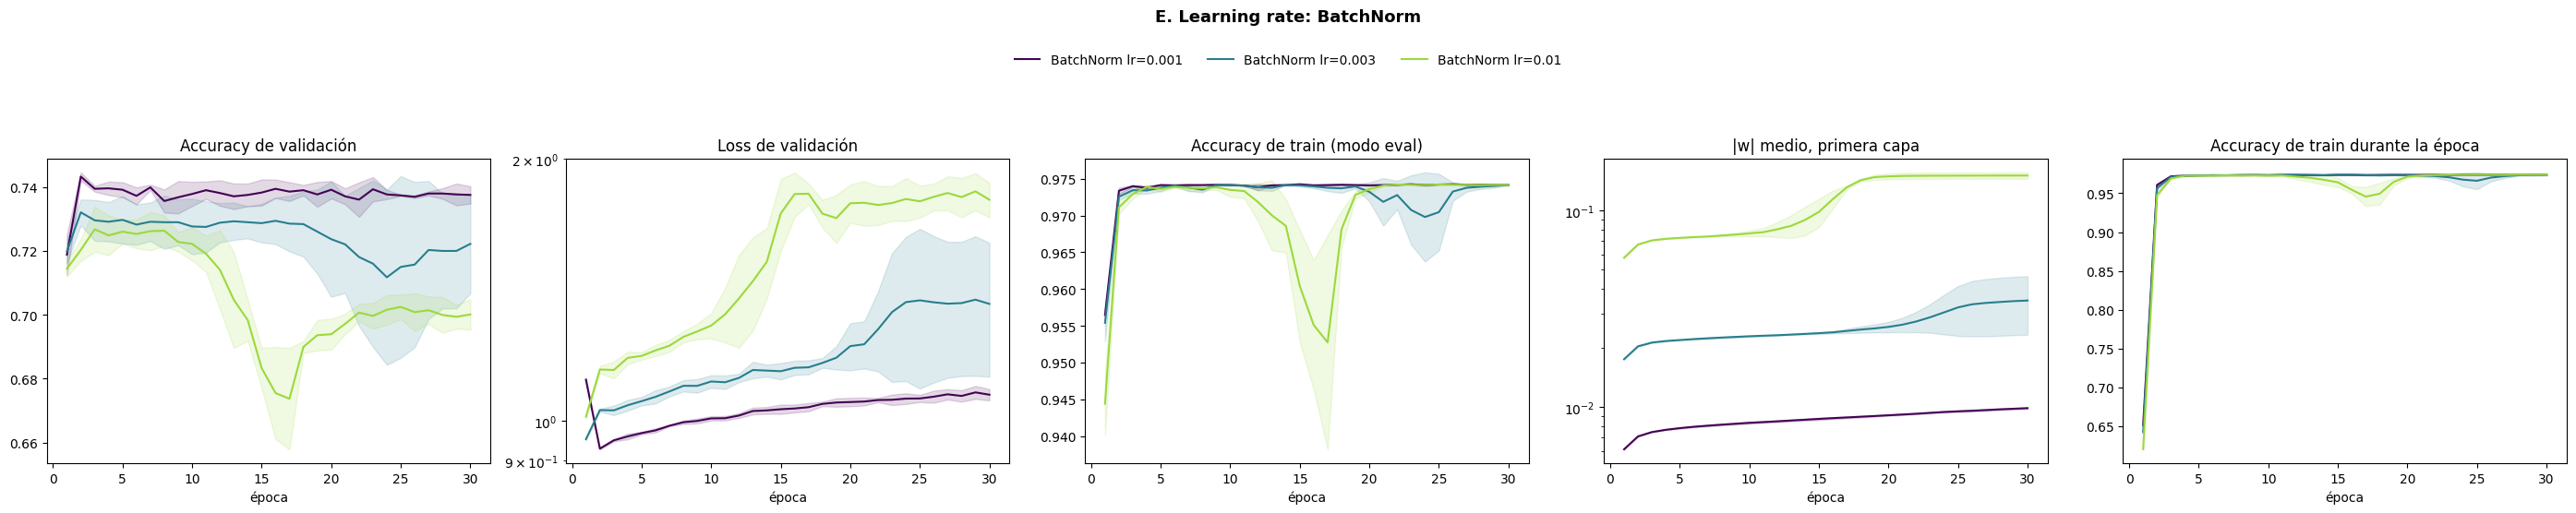

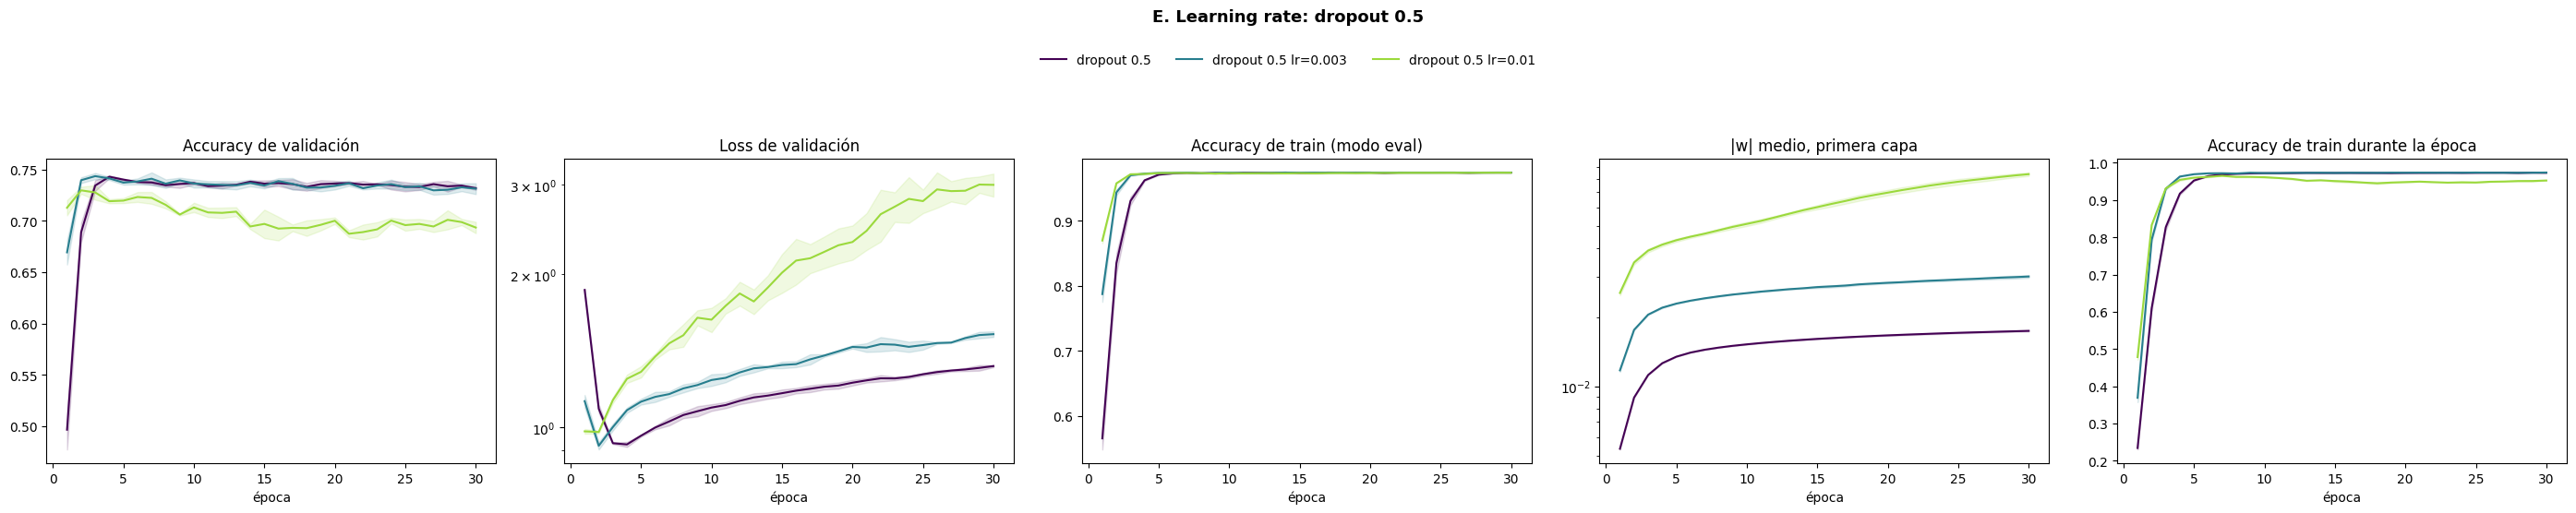

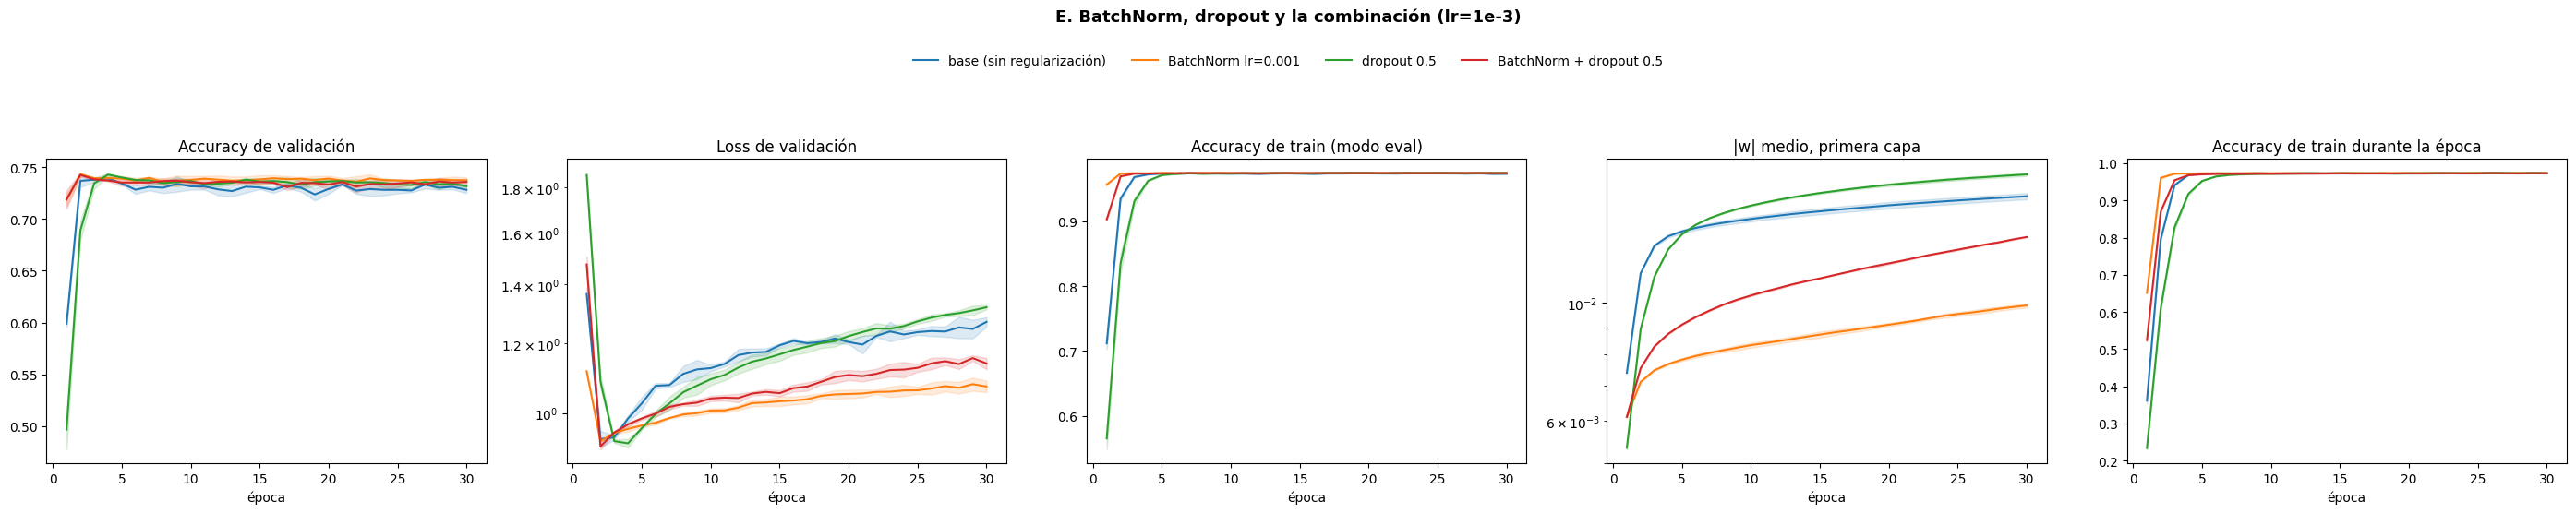

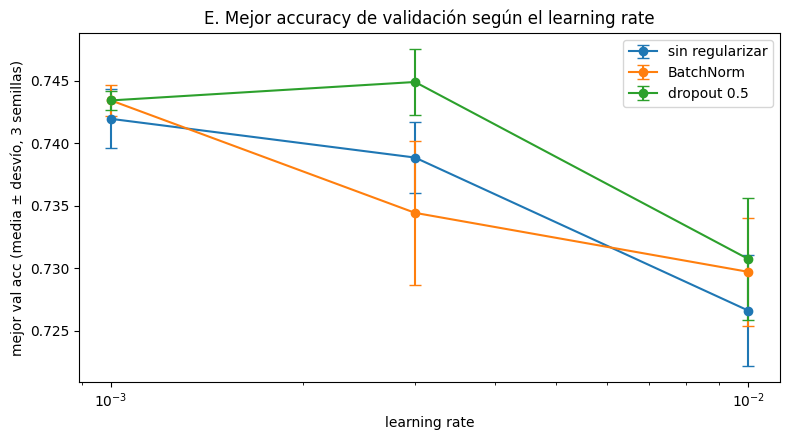

In [ ]:
LR_SWEEP = [1e-3, 3e-3, 1e-2]
namesE = {"sin regularizar": [], "BatchNorm": [], "dropout 0.5": []}
for lr in LR_SWEEP:
    for fam, extra, base_name in [("sin regularizar", {}, "base (sin regularización)"), ("BatchNorm", {"batchnorm": True}, None),
                                  ("dropout 0.5", {"dropout_h": 0.5}, "dropout 0.5")]:
        name = (base_name if (lr == BASE["lr"] and base_name) else f"{fam} lr={lr:g}")
        namesE[fam].append(name)
        run_config(name, {**BASE, **extra, "lr": lr}, "E")
namesE_extra = ["BatchNorm + dropout 0.5"]
run_config("BatchNorm + dropout 0.5", {**BASE, "batchnorm": True, "dropout_h": 0.5}, "E")
allE = sum(namesE.values(), []) + namesE_extra
table(allE)
for fam, names in namesE.items():
    plot_runs(names, f"E. Learning rate: {fam}")
plot_runs(["base (sin regularización)", namesE["BatchNorm"][0], "dropout 0.5", "BatchNorm + dropout 0.5"],
          "E. BatchNorm, dropout y la combinación (lr=1e-3)", ordered=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, (fam, names) in enumerate(namesE.items()):
    mu = [RESULTS[n]["summ"]["mejor val acc"][0] for n in names]
    sd = [RESULTS[n]["summ"]["mejor val acc"][1] for n in names]
    ax.errorbar(LR_SWEEP, mu, yerr=sd, marker="o", capsize=4, label=fam, color=f"C{i}")
ax.set_xscale("log")
ax.set_xlabel("learning rate")
ax.set_ylabel("mejor val acc (media ± desvío, 3 semillas)")
ax.set_title("E. Mejor accuracy de validación según el learning rate")
ax.legend()
plt.tight_layout()
plt.show()

### Análisis E. BatchNorm y learning rate

| learning rate | sin regularizar | BatchNorm | dropout 0.5 |
|---|---|---|---|
| $10^{-3}$ | 0.7419 ± 0.0024 | 0.7434 ± 0.0013 | 0.7434 ± 0.0008 |
| $3\cdot10^{-3}$ | 0.7388 ± 0.0029 | 0.7344 ± 0.0057 | 0.7449 ± 0.0027 |
| $10^{-2}$ | 0.7266 ± 0.0045 | 0.7297 ± 0.0043 | 0.7307 ± 0.0048 |

En las tres variantes, aumentar el learning rate no mejora el resultado. Con $10^{-2}$ la accuracy baja ~1.3 puntos, el máximo se alcanza entre la época 2 y la 4 y luego el modelo se degrada, con una accuracy de validación final de 0.69 a 0.70 y una loss de validación final de 1.8 a 3.0. También aumenta la oscilación de la validación (de 0.008 a 0.010, frente a valores de 0.003 a 0.006 con $10^{-3}$). Por lo tanto, con Adam no se observa la mejora esperada al usar BatchNorm o dropout. Esas recomendaciones están pensadas para SGD, cuyo paso es $\eta g$, mientras que Adam ya normaliza el paso de cada peso y no existe un learning rate bajo impuesto por la escala de los gradientes que BatchNorm o el dropout permitan subir. Otra razón es que la red tiene solo dos capas ocultas, y el *internal covariate shift* que corrige BatchNorm crece con la profundidad.

Con $\eta = 10^{-3}$, BatchNorm no aumenta el máximo (0.7434, igual que dropout 0.5), pero es la configuración más estable al prolongar el entrenamiento. Obtiene la mejor accuracy final de la sección 5 (0.7375 ± 0.0027), la menor loss de validación final (1.072 frente a 1.268 sin regularizar) y la menor oscilación de validación (0.003, igual que dropout 0.7 y dropout con entrada). En el gráfico de la combinación, su curva es la más plana después del máximo, lo que coincide con el leve efecto regularizador de BatchNorm, producido por el ruido de estimar la media y la varianza en cada batch.

Con $\eta = 10^{-2}$, el |w| medio de la primera capa con BatchNorm llega a 0.151, diez veces el de la red base y 2.6 veces el de la red sin BatchNorm con el mismo learning rate, y aun así la red sigue funcionando (0.7297). Esto se explica porque los pesos que entran a una BatchNorm son invariantes a la escala, ya que la normalización cancela cualquier factor que los multiplique. Por eso pueden crecer sin modificar la salida y su magnitud deja de reflejar la confianza del modelo. La relación entre pesos grandes y sobreajuste no se aplica, entonces, a las capas con BatchNorm.

La combinación de BatchNorm con dropout da 0.7427, igual que cada técnica por separado, con una loss final intermedia (1.138). Se suele desaconsejar combinarlas por la interferencia entre ambas. Aquí esa interferencia no se observa, pero tampoco hay una ganancia por combinarlas. En cuanto al costo, BatchNorm agrega solo un 1.5 % por época (0.671 s), porque normaliza 512 valores por capa, una operación menor frente a la multiplicación por la matriz de 40.000 × 512.

## 6. Comparación de todas las técnicas

La tabla contiene una fila por cada configuración entrenada en la sección 5, con las mismas columnas. Los gráficos resumen la relación entre resultado, magnitud de los pesos, ruido y costo. El primero compara la mejor accuracy de validación con el |w| medio de la primera capa, para ver si la regularización que achica los pesos es la que mejor generaliza. El segundo muestra el sobrecosto de tiempo por época respecto de la red base, y el tercero la relación entre el ruido paso a paso y la mejor accuracy de validación.

                         configuración   mejor val acc  ép.   val acc final val loss mín val loss final brecha   |w| L1   |w| L3 % |w|<1e-3 norma unidad máx ruido pasos osc. val train run − eval s/época
             base (sin regularización) 0.7419 ± 0.0024  4.7 0.7282 ± 0.0032        0.925          1.268  0.245 1.58e-02 5.92e-02        3.6           18.603       0.513    0.006           -0.000   0.661
                           L2 λ2=1e-07 0.7400 ± 0.0035  2.7 0.7231 ± 0.0004        0.937          1.291  0.250 1.22e-02 4.91e-02       22.3           11.614       0.512    0.006           -0.000   0.973
                           L2 λ2=1e-06 0.7350 ± 0.0036  2.7 0.7135 ± 0.0048        0.944          1.288  0.260 7.97e-03 4.58e-02       36.9            5.837       0.511    0.006           -0.000   0.973
                           L2 λ2=1e-05 0.7297 ± 0.0032  2.7 0.6920 ± 0.0054        0.962          1.332  0.281 4.89e-03 5.58e-02       48.2            3.002       0.490    0.007           

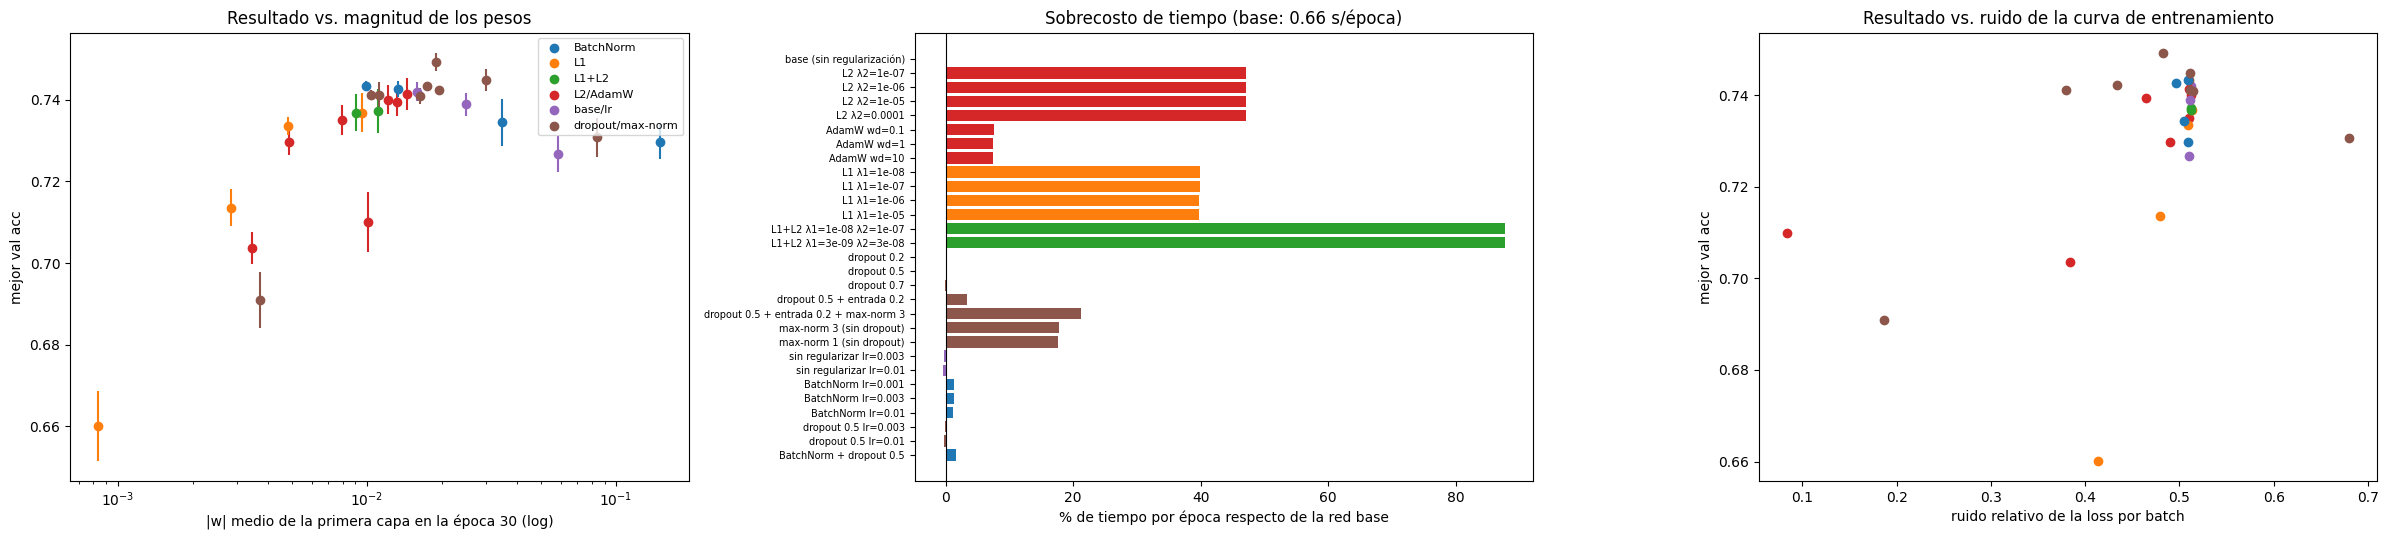

In [ ]:
order = list(dict.fromkeys(namesA + namesB + namesC[3:] + namesD + allE))
table(order)
base_t = RESULTS["base (sin regularización)"]["summ"]["s/época"][0]
fam_of = lambda n: ("L2/AdamW" if n.startswith(("L2", "AdamW")) else "L1" if n.startswith("L1 ") else "L1+L2" if n.startswith("L1+L2")
                    else "BatchNorm" if "BatchNorm" in n else "dropout/max-norm" if ("dropout" in n or "max-norm" in n) else "base/lr")
fig, axes = plt.subplots(1, 3, figsize=(24, 5.5))
fams = sorted(set(fam_of(n) for n in order))
colors = {f: f"C{i}" for i, f in enumerate(fams)}
for n in order:
    s, f = RESULTS[n]["summ"], fam_of(n)
    axes[0].errorbar(s["|w| L1"][0], s["mejor val acc"][0], yerr=s["mejor val acc"][1], fmt="o", color=colors[f])
    axes[2].scatter(s["ruido pasos"][0], s["mejor val acc"][0], color=colors[f])
for f in fams:
    axes[0].scatter([], [], color=colors[f], label=f)
axes[0].set_xscale("log")
axes[0].set_xlabel("|w| medio de la primera capa en la época 30 (log)")
axes[0].set_ylabel("mejor val acc")
axes[0].set_title("Resultado vs. magnitud de los pesos")
axes[0].legend(fontsize=8)
over = [(n, RESULTS[n]["summ"]["s/época"][0] / base_t - 1) for n in order]
axes[1].barh([n for n, _ in over], [100 * v for _, v in over], color=[colors[fam_of(n)] for n, _ in over])
axes[1].invert_yaxis()
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set_xlabel("% de tiempo por época respecto de la red base")
axes[1].set_title(f"Sobrecosto de tiempo (base: {base_t:.2f} s/época)")
axes[1].tick_params(axis="y", labelsize=7)
axes[2].set_xlabel("ruido relativo de la loss por batch")
axes[2].set_ylabel("mejor val acc")
axes[2].set_title("Resultado vs. ruido de la curva de entrenamiento")
plt.tight_layout()
plt.show()

### Análisis de la comparación

En este problema, achicar los pesos no mejora la generalización. Las configuraciones con menor |w| (L1 y L2 fuertes, max-norm 1) son las de peor accuracy, mientras que las mejores con dropout (0.7 y 0.5) tienen pesos iguales o mayores que la red sin regularizar. BatchNorm sí reduce los pesos (9.9e-3), pero en sus capas la magnitud no es relevante, como se vio en el análisis E. La relación entre pesos grandes y sobreajuste aparece en la evolución temporal de la red sin regularizar, cuyos pesos crecen mientras sube la loss de validación. Sin embargo, forzar pesos chicos mediante una penalización no corrige ese problema, y con Adam, según el análisis A, la penalización recae sobre todo en los pesos con poco gradiente.

Una forma de entender por qué L1 y L2 no ayudan y el dropout sí es que el TF-IDF de 40.000 términos es casi linealmente separable con 9.051 documentos, y la red alcanza el techo de train en 3 o 4 épocas con cualquier regularización razonable. Lo que generaliza mal es la confianza que la red asigna a cada palabra, no la cantidad de palabras que utiliza. El dropout y max-norm actúan sobre las unidades ocultas y obligan a que la decisión no dependa de pocas unidades, mientras que L1 y L2 actúan sobre cada peso de entrada, y como los gradientes por palabra son muy desparejos, terminan apagando información útil.

Respecto de la red base (0.661 s por época), el sobrecosto de cada técnica es el siguiente.

| Técnica | Sobrecosto |
|---|---|
| dropout | 0 % |
| BatchNorm | +1.5 % |
| dropout en la entrada | +3 % |
| AdamW | +8 % |
| max-norm | +18 % |
| L1 | +40 % |
| L2 | +47 % |
| L1+L2 | +88 % |

Las penalizaciones en el costo resultan las más caras y, al mismo tiempo, las de peor resultado.

El ruido paso a paso de la loss es prácticamente el mismo (~0.51) en todas las configuraciones que alcanzan el techo de train, porque depende del orden de los batches y no de la técnica. Solo disminuye cuando la regularización impide ajustar el train, como con L2 de 1e-4 (0.38), max-norm 1 (0.19) o AdamW con wd = 10 (0.08). Lo que sí distingue a las técnicas es la oscilación de la validación, que se reduce con dropout y BatchNorm (0.003) y aumenta con un learning rate alto (entre 0.008 y 0.010).

## 7. Elección del modelo con validación

Elegir directamente el mejor trial de la búsqueda introduce un sesgo optimista, porque se toma el máximo de 60 resultados medidos con una sola semilla. Para reducirlo, los 5 mejores trials de la búsqueda y la mejor configuración de cada familia de la sección 5 se vuelven a entrenar con 3 semillas y early stopping (paciencia 5, hasta 30 épocas). Se elige la candidata con mejor accuracy de validación media, y la cantidad de épocas del entrenamiento final es la mejor época media de esas 3 semillas. Todas estas decisiones se toman con validación, sin usar el test.

In [ ]:
cands = {}
for t in sorted(complete, key=lambda t: t.value, reverse=True)[:5]:
    cands[f"Optuna trial #{t.number}"] = t.user_attrs["cfg"]
fam_best = {}
for n in order:
    f = fam_of(n)
    if f == "base/lr":
        continue
    if f not in fam_best or RESULTS[n]["summ"]["mejor val acc"][0] > RESULTS[fam_best[f]]["summ"]["mejor val acc"][0]:
        fam_best[f] = n
for f, n in fam_best.items():
    cands[f"sección 5: {n}"] = RESULTS[n]["cfg"]

sel_rows = []
for name, cfg in cands.items():
    accs, eps = [], []
    for s in SEEDS:
        _, h = train_model(cfg, X_tr, y_tr, X_val, y_val, epochs=MAX_EPOCHS_SEARCH, seed=s, patience=PATIENCE, eval_train=False)
        accs.append(h["best_val_acc"])
        eps.append(h["best_epoch"])
    sel_rows.append({"candidata": name, "val acc media": np.mean(accs), "desvío": np.std(accs), "mejor época media": np.mean(eps),
                     "cfg": cfg})
    print(f"{name:55s} val acc {np.mean(accs):.4f} ± {np.std(accs):.4f} | mejor época {np.mean(eps):.1f}")
if device.type == "cuda":
    torch.cuda.empty_cache()
sel = pd.DataFrame(sel_rows).sort_values("val acc media", ascending=False)
FINAL_NAME = sel.iloc[0]["candidata"]
FINAL_CFG = sel.iloc[0]["cfg"]
FINAL_EPOCHS = int(round(sel.iloc[0]["mejor época media"]))
print(f"\nModelo elegido: {FINAL_NAME} | {FINAL_EPOCHS} épocas | {FINAL_CFG}")
print(f"Diferencia con la segunda candidata: {sel.iloc[0]['val acc media'] - sel.iloc[1]['val acc media']:.4f} "
      f"(error estándar de la validación ≈ {np.sqrt(0.75 * 0.25 / len(idx_val)):.4f})")

Optuna trial #42                                        val acc 0.7696 ± 0.0015 | mejor época 16.7
Optuna trial #51                                        val acc 0.7684 ± 0.0013 | mejor época 11.7
Optuna trial #48                                        val acc 0.7698 ± 0.0025 | mejor época 14.7
Optuna trial #53                                        val acc 0.7680 ± 0.0018 | mejor época 12.0
Optuna trial #26                                        val acc 0.7704 ± 0.0021 | mejor época 14.0
sección 5: AdamW wd=0.1                                 val acc 0.7413 ± 0.0040 | mejor época 2.7
sección 5: L1 λ1=1e-08                                  val acc 0.7368 ± 0.0048 | mejor época 2.7
sección 5: L1+L2 λ1=3e-09 λ2=3e-08                      val acc 0.7372 ± 0.0053 | mejor época 3.0
sección 5: dropout 0.7                                  val acc 0.7492 ± 0.0022 | mejor época 6.7
sección 5: BatchNorm lr=0.001                           val acc 0.7433 ± 0.0013 | mejor época 2.0

Modelo elegido

### Análisis de la elección

Con 3 semillas, los 5 mejores trials de Optuna quedan entre 0.7680 y 0.7704, en un rango de 0.24 puntos. En la búsqueda, con una sola semilla, esos mismos trials habían dado entre 0.7755 y 0.7768 (tabla del top 10), de modo que el máximo de 60 trials sobreestimaba la validación en ~0.6 puntos, que es el sesgo optimista que se buscaba reducir.

Las mejores configuraciones de cada familia de la sección 5 quedan entre 0.7368 y 0.7492, unos 2 o 3 puntos por debajo. Esa diferencia no se debe a la técnica de regularización, sino a la arquitectura y al learning rate. La sección 5 usa deliberadamente una red sobredimensionada (2 × 512 con $\eta = 10^{-3}$) para estudiar la regularización, mientras que la búsqueda encontró una red chica (1 × 256) con $\eta \approx 3.7\cdot10^{-4}$.

Se eligió el trial #26, con una capa de 256 unidades ReLU, batch 128, $\eta = 3.7\cdot10^{-4}$, dropout de entrada 0.20, dropout oculto 0.35, max-norm 5, sin L1 ni L2 y sin BatchNorm, entrenado 14 épocas (la mejor época media). Su ventaja sobre la segunda candidata, de 0.0006, es mucho menor que el error estándar (0.009), por lo que las cinco candidatas de Optuna son equivalentes. Todas comparten las mismas técnicas, que son dropout en la entrada y en la capa oculta y max-norm.

## 8. Evaluación final en test (una sola vez)

Se reentrenan tres modelos con **todo** el train (11.314 documentos, con el vectorizador ajustado nuevamente sobre todo el train) y se evalúan en test con 3 semillas cada uno. El primero es el modelo regularizado elegido en la sección 7, con sus épocas. El segundo es la red base sin regularizar (2 × 512), con la misma cantidad de épocas, para medir cuánto aporta la regularización. El tercero es el modelo final del TP2 (una capa de 1024 unidades, ELU, dropout 0.08, Adam con $\eta = 2.3\cdot10^{-4}$, $\beta_1=0.649$ y $\beta_2=0.952$, batch 256 y 15 épocas), como referencia respecto del trabajo anterior.

Se informa la media ± el desvío entre semillas y el error estándar binomial del test. Después de esta celda no se modifica ninguna decisión.

In [ ]:
del X_tr, X_val
if device.type == "cuda":
    torch.cuda.empty_cache()
vec_f = TfidfVectorizer(ngram_range=PREPRO["ngram_range"], max_features=PREPRO["max_features"], min_df=PREPRO["min_df"])
X_full = to_device_dense(vec_f.fit_transform(train_proc))
X_test = to_device_dense(vec_f.transform(test_proc))
y_full = torch.tensor(y_train_all, dtype=torch.long, device=device)
y_test = torch.tensor(y_test_all, dtype=torch.long, device=device)

TP2_CFG = {"hidden": [1024], "activation": "elu", "dropout_h": 0.07613861387437061, "lr": 0.00023270677083837802,
           "beta1": 0.6490786990501735, "beta2": 0.9524231675200606, "batch_size": 256}
FINALS = [("Modelo regularizado elegido", FINAL_CFG, FINAL_EPOCHS),
          ("Red base sin regularizar (2x512)", BASE, FINAL_EPOCHS),
          ("Modelo final del TP2", TP2_CFG, 15)]
final_rows, final_preds = [], {}
for name, cfg, ep in FINALS:
    accs, f1s, times = [], [], []
    for s in SEEDS:
        model, h = train_model(cfg, X_full, y_full, None, None, epochs=ep, seed=s, eval_train=False)   # sin mirar test
        model.eval()
        with torch.no_grad():
            pred = torch.cat([model(X_test[i:i + 4096]).argmax(1) for i in range(0, len(X_test), 4096)]).cpu().numpy()
        accs.append(accuracy_score(y_test_all, pred))
        f1s.append(f1_score(y_test_all, pred, average="macro"))
        times.append(h["train_time"])
        if s == SEEDS[0]:
            final_preds[name] = pred
        del model
    final_rows.append({"modelo": name, "épocas": ep, "parámetros": h["n_params"], "test acc": f"{np.mean(accs):.4f} ± {np.std(accs):.4f}",
                       "F1 macro": f"{np.mean(f1s):.4f} ± {np.std(f1s):.4f}", "seg de entrenamiento": f"{np.mean(times):.1f}"})
    with mlflow.start_run(run_name=f"final_{name}"):
        mlflow.log_params({k: str(v) for k, v in cfg.items()} | {"epochs": ep})
        mlflow.log_metrics({"test_acc_mean": float(np.mean(accs)), "test_f1_macro_mean": float(np.mean(f1s))})
print(pd.DataFrame(final_rows).to_string(index=False))
print(f"\nError estándar binomial del test ({len(y_test_all)} documentos) para una accuracy de 0.70: "
      f"±{np.sqrt(0.7 * 0.3 / len(y_test_all)):.4f}")
print("\nReporte por clase del modelo regularizado (semilla 0):")
print(classification_report(y_test_all, final_preds["Modelo regularizado elegido"], target_names=class_names, digits=3))

                          modelo  épocas  parámetros        test acc        F1 macro seg de entrenamiento
     Modelo regularizado elegido      14    10245396 0.7065 ± 0.0006 0.6954 ± 0.0013                  7.4
Red base sin regularizar (2x512)      14    20753428 0.6663 ± 0.0022 0.6605 ± 0.0002                 11.5
            Modelo final del TP2      15    40981524 0.7093 ± 0.0012 0.7004 ± 0.0014                 15.6

Error estándar binomial del test (7532 documentos) para una accuracy de 0.70: ±0.0053

Reporte por clase del modelo regularizado (semilla 0):
                          precision    recall  f1-score   support

             alt.atheism      0.520     0.524     0.522       319
           comp.graphics      0.646     0.704     0.674       389
 comp.os.ms-windows.misc      0.644     0.612     0.628       394
comp.sys.ibm.pc.hardware      0.666     0.625     0.645       392
   comp.sys.mac.hardware      0.755     0.712     0.733       385
          comp.windows.x      0.797 

### Análisis de la evaluación final

| Modelo | Parámetros | Test acc | F1 macro | Entrenamiento |
|---|---|---|---|---|
| Regularizado elegido (1 × 256, dropout + max-norm) | 10.2 M | 0.7065 ± 0.0006 | 0.6954 ± 0.0013 | 7.4 s |
| Red base sin regularizar (2 × 512) | 20.8 M | 0.6663 ± 0.0022 | 0.6605 ± 0.0002 | 11.5 s |
| Modelo final del TP2 (1 × 1024, dropout 0.08) | 41.0 M | 0.7093 ± 0.0012 | 0.7004 ± 0.0014 | 15.6 s |

El error estándar binomial del test es de ±0.0053.

El modelo regularizado supera a la red sin regularizar por 4.0 puntos, muy por encima del error estándar y del desvío entre semillas. Esta comparación incluye dos efectos, ya que la arquitectura y el learning rate son distintos y la red base se entrena 14 épocas cuando en validación su máximo estaba en la época 5. Lo que mide, entonces, es cuánto se gana con una configuración regularizada que tolera entrenar más allá del óptimo, y no el efecto aislado del dropout.

Frente al modelo del TP2, la diferencia es de −0.3 puntos de accuracy y −0.5 de F1, en ambos casos menor que el error estándar, por lo que los dos modelos son equivalentes. El de este TP tiene la cuarta parte de los parámetros y se entrena en la mitad del tiempo. Cabe notar que el modelo del TP2 también usaba dropout (0.08), de modo que ambos son variantes regularizadas de una red de una capa.

El modelo elegido pasa de 0.7704 en validación a 0.7065 en test, una caída de 6.4 puntos similar a la del TP2. Como se analizó en el TP1, `fetch_20newsgroups` separa train y test por fecha, por lo que el test contiene mensajes posteriores a los de train y la validación, que es una parte al azar del train, resulta una estimación optimista.

Por clase se repiten los patrones del TP2. `rec.autos` tiene un recall alto (0.801) y una precisión baja (0.504), lo que en el TP2 se explicó por los documentos con vector TF-IDF nulo que el modelo asigna a esa clase, y `talk.religion.misc` sigue siendo la clase peor reconocida (recall 0.243).

## 9. Conclusiones

L1 y L2 modifican los pesos de la forma esperada. L2 los achica y L1 los vuelve esparsos, al punto de que con L1 se puede podar el 98.5 % de la primera capa sin perder accuracy. Sin embargo, en este problema ninguna de las dos mejora la validación, y el resultado empeora a medida que crece $\lambda$. Con Adam, la L2 incluida en la función de costo afectaría sobre todo a los pesos de las palabras poco frecuentes, porque el optimizador amplifica el gradiente de la penalización donde el gradiente de los datos es chico. El weight decay desacoplado (AdamW) encoge todos los pesos por igual y reduce la sobreconfianza (menor loss de validación final), aunque tampoco mejora el máximo. La combinación L1+L2 no aporta nada respecto de L1.

El dropout es la única técnica que mejora levemente la accuracy (0.7 puntos con una tasa de 0.7) y está presente en todas las configuraciones elegidas por Optuna, junto con el dropout en la entrada y max-norm 5. No achica los pesos, sino que reparte la información entre las unidades, como muestra la caída de la norma máxima por unidad de 18.6 a 7.4. Max-norm limita la confianza de cada unidad y reduce la loss de validación final sin mejorar el máximo.

BatchNorm no mejora el máximo, pero produce el entrenamiento más estable, con la mejor accuracy final y la menor loss final después de 30 épocas. En las capas con BatchNorm la magnitud de los pesos pierde significado, porque esos pesos son invariantes a la escala.

Con Adam y una red de dos capas, ni BatchNorm ni el dropout permitieron usar learning rates mayores, posiblemente porque esas recomendaciones están pensadas para SGD, cuyo paso no se normaliza, algo que no se probó en este trabajo. El dropout y BatchNorm reducen la oscilación de la curva de validación y los learning rates altos la aumentan, mientras que el ruido de la loss por batch depende del orden de los batches y no permite distinguir entre técnicas, porque con 21 millones de parámetros todas las variantes alcanzan el techo de train. En cuanto al tiempo, las penalizaciones en el costo son lo más caro (entre un 40 y un 88 % más por época), y el dropout y BatchNorm casi no agregan costo.

El modelo elegido, de una capa de 256 unidades con dropout y max-norm, alcanza 0.7065 en test. Es equivalente al del TP2 con la cuarta parte de los parámetros y supera por 4 puntos a la red sobredimensionada sin regularizar. En este problema, lo más importante es elegir una capacidad adecuada y un learning rate bajo, y entre las técnicas de regularización la más útil resultó ser el dropout.

## 10. Declaración de uso de herramientas de IA

Se utilizó Claude (Anthropic) como herramienta de asistencia durante el desarrollo del presente trabajo práctico. Principalmente, se recurrió a la herramienta para mejorar la redacción de las explicaciones, organizar los análisis y revisar la claridad y coherencia de los contenidos presentados.

También se utilizó como apoyo para consultar conceptos teóricos relacionados con los temas abordados, revisar la implementación de algunos procedimientos, verificar la consistencia de los análisis y discutir la interpretación de los resultados obtenidos.

La herramienta fue utilizada como complemento del proceso de trabajo, especialmente en las instancias de revisión, corrección y elaboración de las explicaciones y conclusiones.